# Proximity-Variance Sampling: Shortest Path Analysis

This notebook mirrors `plot_shortest_path.ipynb` but uses the **proximity-variance** dataset
(`res04_proximity_variance.npz`) and the model trained on it.

The goal is to compare whether irregular sampling (biasing sources toward steep terrain
and targets toward nearby nodes) improves prediction quality for:

- **close-together pairs** (short straight-line distance)
- **high-elevation / steep-terrain pairs**

## Load dataset and build graph

In [17]:
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd


DATASET_PATH = Path("../data/res04_hybrid.npz")


def infer_grid(node_features: np.ndarray):
    unique_x = np.unique(node_features[:, 0])
    unique_y = np.unique(node_features[:, 1])
    rows = len(unique_y)
    cols = len(unique_x)
    if rows * cols != len(node_features):
        raise ValueError(
            f"Could not reshape node_features into a grid: rows={rows}, cols={cols}, "
            f"num_nodes={len(node_features)}"
        )

    x_grid = node_features[:, 0].reshape(rows, cols)
    y_grid = node_features[:, 1].reshape(rows, cols)
    z_grid = node_features[:, 2].reshape(rows, cols)
    return x_grid, y_grid, z_grid


def build_weighted_graph(edge_index: np.ndarray, distances: np.ndarray) -> nx.Graph:
    graph = nx.Graph()

    unique_edge_mask = edge_index[0] < edge_index[1]
    for u, v, w in zip(
        edge_index[0, unique_edge_mask],
        edge_index[1, unique_edge_mask],
        distances[unique_edge_mask],
    ):
        graph.add_edge(int(u), int(v), weight=float(w))

    return graph


def compute_pair_table(node_features, srcs, tars, lengths):
    straight_line = np.linalg.norm(node_features[tars] - node_features[srcs], axis=1)
    detour_ratio = np.divide(
        lengths,
        straight_line,
        out=np.full(len(lengths), np.nan, dtype=float),
        where=straight_line > 0,
    )

    return pd.DataFrame(
        {
            "pair_idx": np.arange(len(srcs)),
            "src": srcs,
            "tar": tars,
            "shortest_length": lengths,
            "straight_line": straight_line,
            "detour_ratio": detour_ratio,
        }
    )


def path_cumulative_distance(path_xyz: np.ndarray) -> np.ndarray:
    step_lengths = np.linalg.norm(np.diff(path_xyz, axis=0), axis=1)
    return np.concatenate([[0.0], np.cumsum(step_lengths)])


def compute_altitude_variance(node_features, rows, cols):
    z = np.asarray(node_features)[:, 2].reshape(rows, cols)
    gy = np.empty_like(z)
    gx = np.empty_like(z)
    gy[1:-1, :] = (z[2:, :] - z[:-2, :]) / 2
    gy[0, :] = z[1, :] - z[0, :]
    gy[-1, :] = z[-1, :] - z[-2, :]
    gx[:, 1:-1] = (z[:, 2:] - z[:, :-2]) / 2
    gx[:, 0] = z[:, 1] - z[:, 0]
    gx[:, -1] = z[:, -1] - z[:, -2]
    return np.sqrt(gx**2 + gy**2).ravel()


def plot_pair(pair_idx: int, *, zoom_margin: float = 0.2):
    row = pair_table.loc[pair_idx]
    src = int(row["src"])
    tar = int(row["tar"])

    path_nodes = nx.shortest_path(graph, src, tar, weight="weight")
    path_xyz = node_features[path_nodes]
    cumulative_distance = path_cumulative_distance(path_xyz)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    terrain_ax = axes[0]
    z_view = z_grid[
        (y_grid >= (min(node_features[src, 1], node_features[tar, 1], path_xyz[:, 1].min()) - zoom_margin))
        & (y_grid <= (max(node_features[src, 1], node_features[tar, 1], path_xyz[:, 1].max()) + zoom_margin))
        & (x_grid >= (min(node_features[src, 0], node_features[tar, 0], path_xyz[:, 0].min()) - zoom_margin))
        & (x_grid <= (max(node_features[src, 0], node_features[tar, 0], path_xyz[:, 0].max()) + zoom_margin))
    ]
    levels = 40
    if z_view.size > 0:
        z_lo, z_hi = z_view.min(), z_view.max()
        if z_hi - z_lo > 1e-6:
            levels = np.linspace(z_lo, z_hi, 50)

    terrain = terrain_ax.contourf(x_grid, y_grid, z_grid, levels=levels, cmap="terrain")
    fig.colorbar(terrain, ax=terrain_ax, label="Elevation (km)")

    terrain_ax.plot(path_xyz[:, 0], path_xyz[:, 1], color="crimson", linewidth=2.5, label="Shortest path")
    terrain_ax.scatter(node_features[src, 0], node_features[src, 1], color="blue", s=80, label="Source", zorder=5)
    terrain_ax.scatter(node_features[tar, 0], node_features[tar, 1], color="gold", edgecolor="black", s=80, label="Target", zorder=5)
    terrain_ax.plot(
        [node_features[src, 0], node_features[tar, 0]],
        [node_features[src, 1], node_features[tar, 1]],
        linestyle="--", color="white", linewidth=1.5, alpha=0.8, label="Straight line",
    )

    x_min = min(node_features[src, 0], node_features[tar, 0], path_xyz[:, 0].min()) - zoom_margin
    x_max = max(node_features[src, 0], node_features[tar, 0], path_xyz[:, 0].max()) + zoom_margin
    y_min = min(node_features[src, 1], node_features[tar, 1], path_xyz[:, 1].min()) - zoom_margin
    y_max = max(node_features[src, 1], node_features[tar, 1], path_xyz[:, 1].max()) + zoom_margin
    terrain_ax.set_xlim(x_min, x_max)
    terrain_ax.set_ylim(y_min, y_max)
    terrain_ax.set_aspect("equal")
    terrain_ax.set_xlabel("x (km)")
    terrain_ax.set_ylabel("y (km)")
    terrain_ax.legend(loc="best")
    terrain_ax.set_title(
        f"Pair {pair_idx}: src={src}, tar={tar}\n"
        f"shortest={row['shortest_length']:.3f} km, straight={row['straight_line']:.3f} km, "
        f"ratio={row['detour_ratio']:.3f}"
    )

    profile_ax = axes[1]
    profile_ax.plot(cumulative_distance, path_xyz[:, 2], color="crimson", linewidth=2)
    profile_ax.scatter(cumulative_distance[0], path_xyz[0, 2], color="blue", s=50, zorder=5)
    profile_ax.scatter(cumulative_distance[-1], path_xyz[-1, 2], color="gold", edgecolor="black", s=50, zorder=5)
    profile_ax.set_xlabel("Distance along path (km)")
    profile_ax.set_ylabel("Elevation (km)")
    profile_ax.set_title(
        f"Elevation profile\n"
        f"max elevation on path = {path_xyz[:, 2].max():.3f} km"
    )
    profile_ax.grid(alpha=0.3)

    plt.tight_layout()
    return fig, path_nodes


npz_path = DATASET_PATH.resolve()
data = np.load(npz_path)
node_features = data["node_features"]
edge_index = data["edge_index"]
distances = data["distances"]
srcs = data["srcs"]
tars = data["tars"]
lengths = data["lengths"]

x_grid, y_grid, z_grid = infer_grid(node_features)
rows, cols = z_grid.shape
alt_var = compute_altitude_variance(node_features, rows, cols)
graph = build_weighted_graph(edge_index, distances)
pair_table = compute_pair_table(node_features, srcs, tars, lengths).set_index("pair_idx")

print(f"Loaded: {npz_path}")
print(f"Nodes: {len(node_features):,}")
print(f"Undirected edges: {graph.number_of_edges():,}")
print(f"Pairs: {len(srcs):,}")
print(f"Unique sources: {len(np.unique(srcs)):,}")
print(f"Unique targets: {len(np.unique(tars)):,}")

Loaded: /home/teresa/shortest-paths-nn/data/res04_hybrid.npz
Nodes: 250,000
Undirected edges: 997,002
Pairs: 1,000,000
Unique sources: 1,000
Unique targets: 245,397


In [18]:
interesting_pairs = (
    pair_table[pair_table["straight_line"] > 0]
    .sort_values(["detour_ratio", "shortest_length"], ascending=[False, False])
    .drop_duplicates(subset=["src"])
    .head(12)
)

interesting_pairs[["src", "tar", "shortest_length", "straight_line", "detour_ratio"]]

,src,tar,shortest_length,straight_line,detour_ratio
pair_idx,,,,,
902901,127404,129903,0.667177,0.216127,3.086961
714567,9825,10828,0.429614,0.144981,2.963236
695463,54632,55629,0.435689,0.154564,2.818829
679995,820,822,0.423746,0.150541,2.814814
897557,66902,63903,0.679812,0.243846,2.787875
945900,3816,323,1.136036,0.414273,2.742239
500614,89146,89147,0.212764,0.078902,2.696538
980861,46912,48912,0.431592,0.160674,2.686136
990833,211862,217360,1.193239,0.447699,2.665271


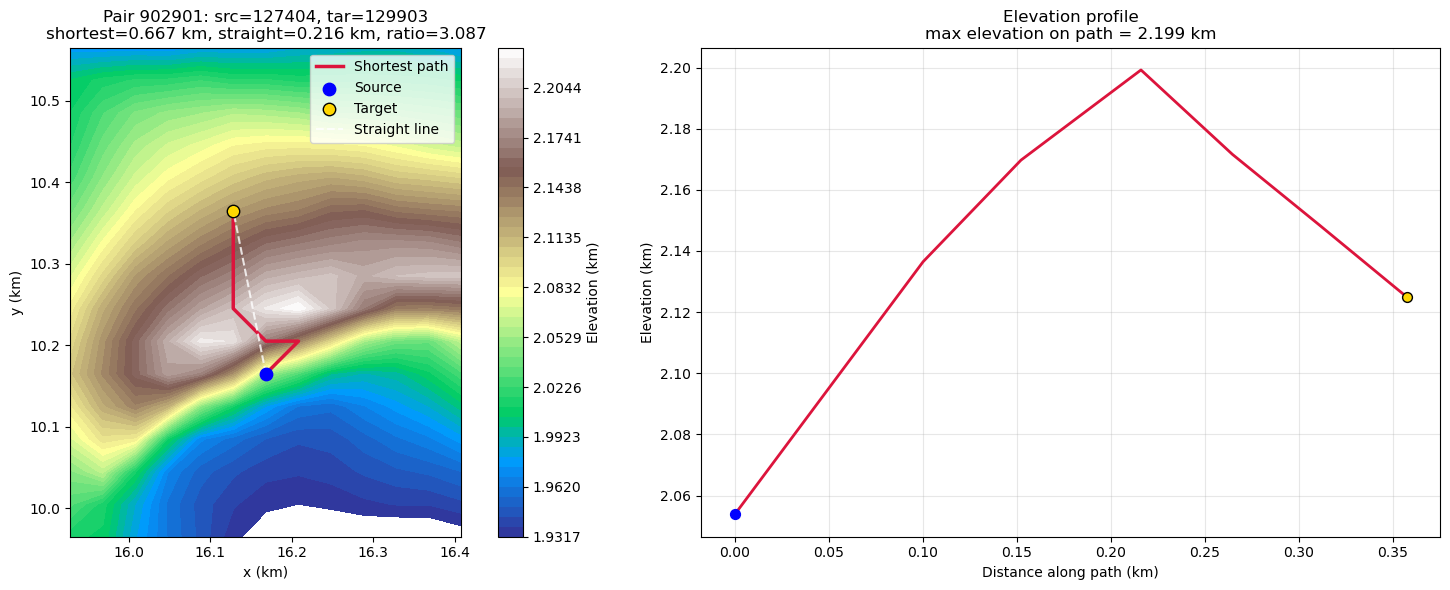

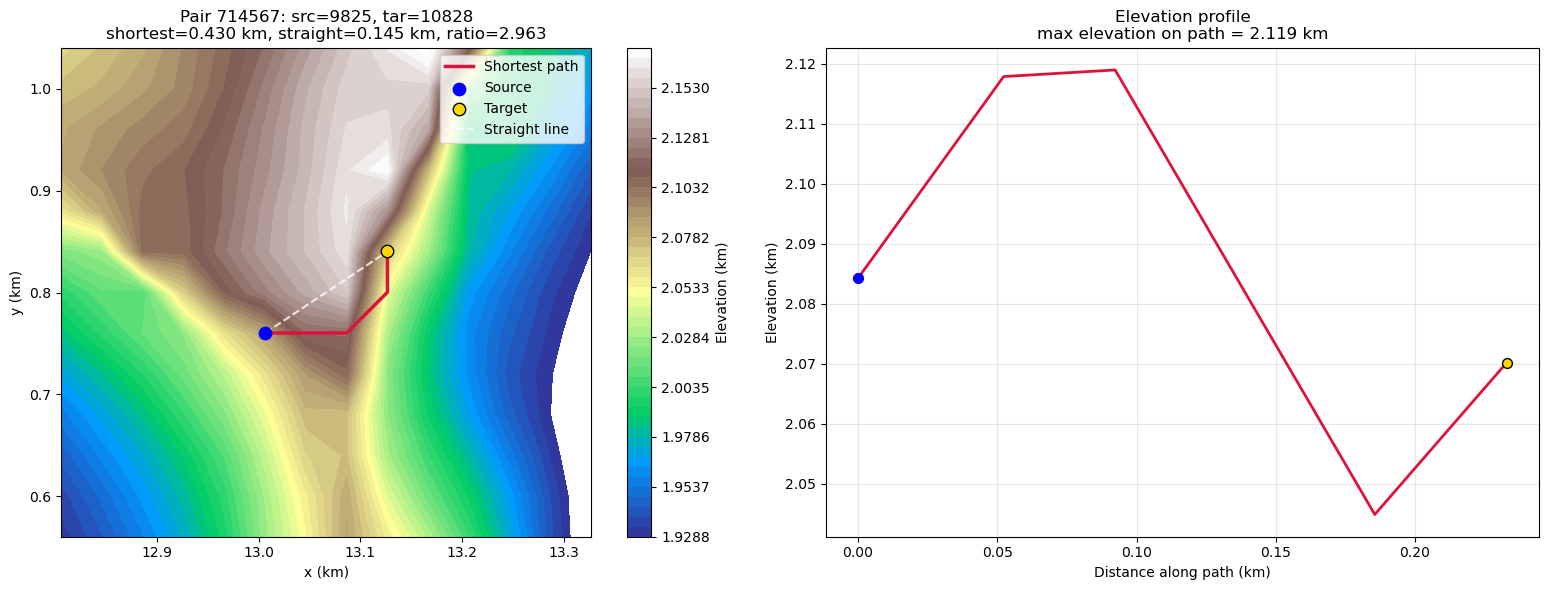

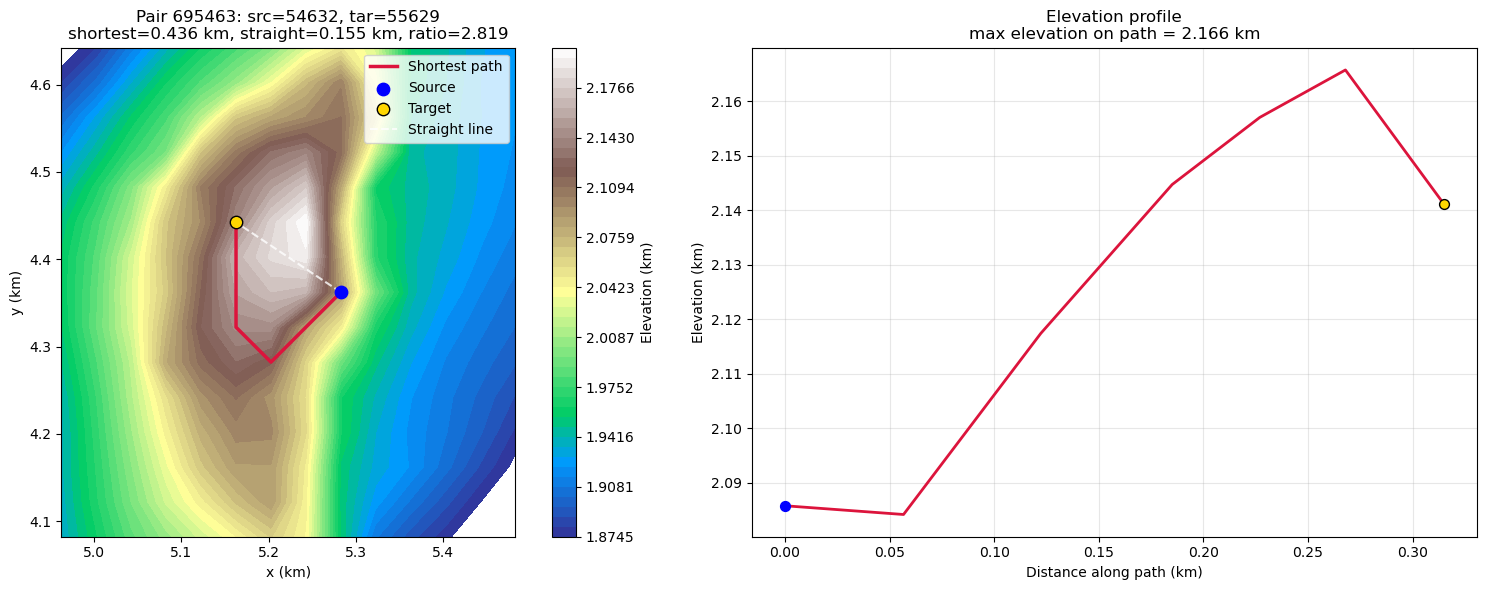

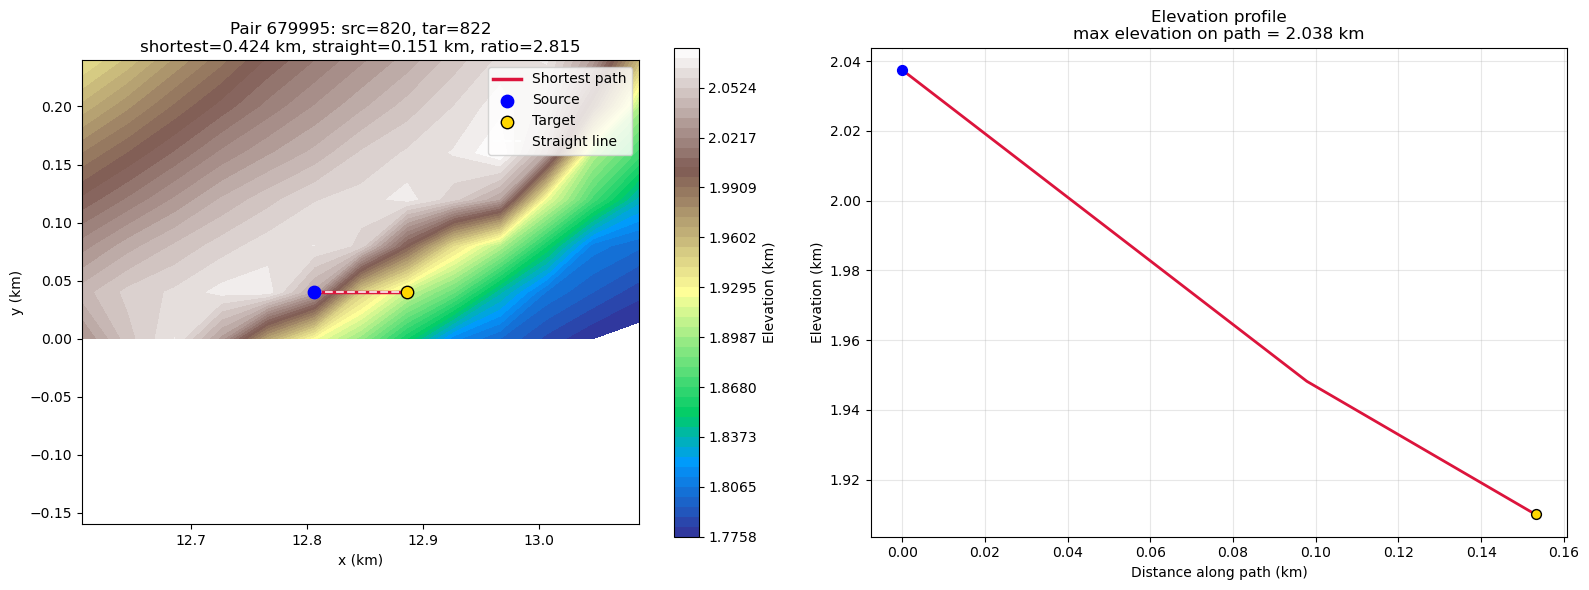

Path has 7 nodes


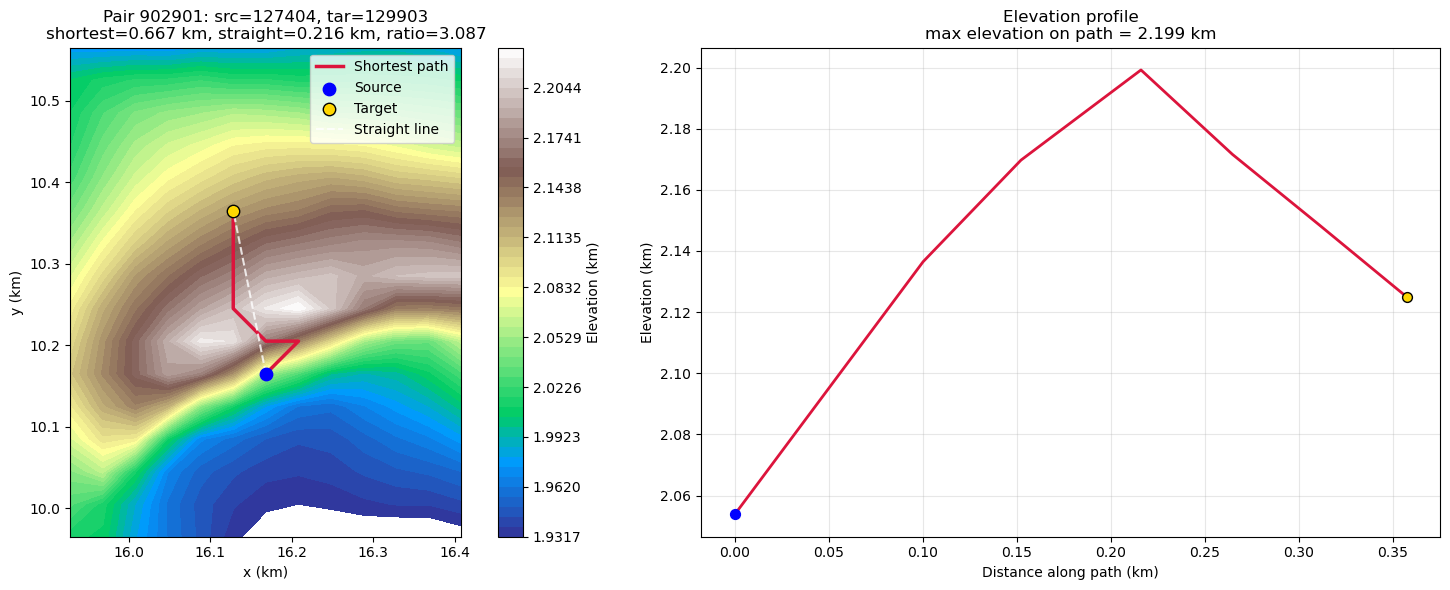

In [19]:
for pair_idx in interesting_pairs.index[:4]:
    fig, path_nodes = plot_pair(int(pair_idx))
    plt.show()

PAIR_IDX = int(interesting_pairs.index[0])
fig, path_nodes = plot_pair(PAIR_IDX)
print(f"Path has {len(path_nodes)} nodes")
plt.show()

## Medium- and long-distance shortest paths

The high-detour examples above can be dominated by very local paths. This section stratifies pairs by straight-line distance, then visualizes representative medium-distance and long-distance shortest paths on the terrain.

In [ ]:
N_DISTANCE_EXAMPLES = 4

nonzero_pairs = pair_table[pair_table["straight_line"] > 0].copy()
q45, q55, q90 = nonzero_pairs["straight_line"].quantile([0.45, 0.55, 0.90])

medium_distance_pairs = (
    nonzero_pairs[
        (nonzero_pairs["straight_line"] >= q45)
        & (nonzero_pairs["straight_line"] <= q55)
    ]
    .sort_values(["detour_ratio", "shortest_length"], ascending=[False, False])
    .drop_duplicates(subset=["src"])
    .head(N_DISTANCE_EXAMPLES)
)

long_distance_pairs = (
    nonzero_pairs[nonzero_pairs["straight_line"] >= q90]
    .sort_values(["straight_line", "detour_ratio"], ascending=[False, False])
    .drop_duplicates(subset=["src"])
    .head(N_DISTANCE_EXAMPLES)
)

path_groups = {
    "Medium distance": medium_distance_pairs,
    "Long distance": long_distance_pairs,
}

for group_name, group_df in path_groups.items():
    print(f"{group_name} examples")
    display(group_df[["src", "tar", "shortest_length", "straight_line", "detour_ratio"]])


def plot_distance_stratified_paths(path_groups, *, zoom_padding_fraction=0.15):
    n_rows = len(path_groups)
    n_cols = max(len(group_df) for group_df in path_groups.values())
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.5 * n_cols, 4.2 * n_rows), squeeze=False)

    for row_idx, (group_name, group_df) in enumerate(path_groups.items()):
        for col_idx, (pair_idx, pair_row) in enumerate(group_df.iterrows()):
            ax = axes[row_idx, col_idx]
            src = int(pair_row["src"])
            tar = int(pair_row["tar"])
            path_nodes = nx.shortest_path(graph, src, tar, weight="weight")
            path_xyz = node_features[path_nodes]

            terrain = ax.contourf(x_grid, y_grid, z_grid, levels=40, cmap="terrain")
            ax.plot(
                [node_features[src, 0], node_features[tar, 0]],
                [node_features[src, 1], node_features[tar, 1]],
                linestyle="--",
                color="white",
                linewidth=1.2,
                alpha=0.75,
            )
            ax.plot(path_xyz[:, 0], path_xyz[:, 1], color="crimson", linewidth=2.2)
            ax.scatter(node_features[src, 0], node_features[src, 1], color="blue", s=45, zorder=5)
            ax.scatter(
                node_features[tar, 0],
                node_features[tar, 1],
                color="gold",
                edgecolor="black",
                s=45,
                zorder=5,
            )

            x_min = min(node_features[src, 0], node_features[tar, 0], path_xyz[:, 0].min())
            x_max = max(node_features[src, 0], node_features[tar, 0], path_xyz[:, 0].max())
            y_min = min(node_features[src, 1], node_features[tar, 1], path_xyz[:, 1].min())
            y_max = max(node_features[src, 1], node_features[tar, 1], path_xyz[:, 1].max())
            margin = max(0.2, zoom_padding_fraction * max(x_max - x_min, y_max - y_min))
            ax.set_xlim(x_min - margin, x_max + margin)
            ax.set_ylim(y_min - margin, y_max + margin)
            ax.set_aspect("equal")
            ax.set_xlabel("x (km)")
            ax.set_ylabel("y (km)")
            ax.set_title(
                f"{group_name}\n"
                f"pair={pair_idx}, straight={pair_row['straight_line']:.2f} km\n"
                f"shortest={pair_row['shortest_length']:.2f} km, ratio={pair_row['detour_ratio']:.2f}"
            )

        for empty_col_idx in range(len(group_df), n_cols):
            axes[row_idx, empty_col_idx].axis("off")

    handles = [
        plt.Line2D([0], [0], color="crimson", linewidth=2.2, label="Shortest path"),
        plt.Line2D([0], [0], color="white", linestyle="--", linewidth=1.2, label="Straight line"),
        plt.Line2D([0], [0], marker="o", color="blue", linestyle="", label="Source"),
        plt.Line2D(
            [0],
            [0],
            marker="o",
            markerfacecolor="gold",
            markeredgecolor="black",
            color="black",
            linestyle="",
            label="Target",
        ),
    ]
    fig.legend(handles=handles, loc="upper center", ncol=len(handles), bbox_to_anchor=(0.5, 1.02))
    fig.colorbar(terrain, ax=axes.ravel().tolist(), shrink=0.82, label="Elevation (km)")
    fig.suptitle("Shortest paths by straight-line distance regime", y=1.08, fontsize=15)
    return fig


fig = plot_distance_stratified_paths(path_groups)
plt.show()

In [20]:
import torch

## Model comparison: TAGConv vs SparseGT (hybrid sampling)

The cells below load predictions from both **TAGConv** and **SparseGT** trained on the hybrid dataset,
align them with the test set, and show side-by-side comparisons of:

- summary metrics
- predicted vs true distance scatter
- error distributions
- error breakdowns by proximity and elevation

In [21]:
from pathlib import Path

TEST_DATA_PATH = Path("../data/generated2/full_test-004.npz")

PREDS_GLOBS = {
    "TAGConv": "models/single_dataset/norway/res04/mse_loss/tagconv-k3/1/runs/terrain-graph-TAGConv-res04-stage1_*/preds.csv",
    "SparseGT": "models/single_dataset/norway/res04/mse_loss/sparse-gt-rpearl/1/runs/terrain-graph-SparseGT-res04-stage1_*/preds.csv",
}


def resolve_latest_preds_path(glob_pattern: str) -> Path:
    root = Path("..")
    candidates = sorted(
        root.glob(glob_pattern),
        key=lambda p: p.stat().st_mtime,
        reverse=True,
    )
    if not candidates:
        raise FileNotFoundError(f"No preds.csv found for pattern: {glob_pattern}")
    return candidates[0].resolve()


def recreate_test_indices(num_pairs: int, val_fraction: float = 0.005, seed: int = 42) -> np.ndarray:
    n_val = max(1, int(num_pairs * val_fraction))
    generator = torch.Generator().manual_seed(seed)
    indices = torch.randperm(num_pairs, generator=generator).tolist()
    return np.array(indices[n_val:], dtype=int)


def load_test_pair_table():
    test_data = np.load(TEST_DATA_PATH)
    test_srcs = test_data["srcs"]
    test_tars = test_data["tars"]
    test_lengths = test_data["lengths"]
    test_nf = test_data["node_features"]

    test_straight_line = np.linalg.norm(test_nf[test_tars] - test_nf[test_srcs], axis=1)
    test_detour_ratio = np.divide(
        test_lengths, test_straight_line,
        out=np.full(len(test_lengths), np.nan, dtype=float),
        where=test_straight_line > 0,
    )
    return pd.DataFrame({
        "pair_idx": np.arange(len(test_srcs)),
        "src": test_srcs,
        "tar": test_tars,
        "shortest_length": test_lengths,
        "straight_line": test_straight_line,
        "detour_ratio": test_detour_ratio,
    })


def load_prediction_results(glob_pattern: str, test_pair_table: pd.DataFrame) -> pd.DataFrame:
    preds_path = resolve_latest_preds_path(glob_pattern)
    preds_df = pd.read_csv(preds_path)
    preds_df["srcs"] = preds_df["srcs"].astype(int)
    preds_df["tars"] = preds_df["tars"].astype(int)

    test_indices = recreate_test_indices(len(test_pair_table))
    if len(preds_df) != len(test_indices):
        raise ValueError(
            f"Prediction row count ({len(preds_df)}) does not match "
            f"recreated test split ({len(test_indices)})."
        )

    aligned_pairs = test_pair_table.iloc[test_indices].reset_index(drop=True)
    results = pd.concat([aligned_pairs, preds_df], axis=1)

    if not (
        np.array_equal(results["src"].to_numpy(), results["srcs"].to_numpy())
        and np.array_equal(results["tar"].to_numpy(), results["tars"].to_numpy())
    ):
        raise ValueError("Recreated test split did not align with preds.csv rows.")

    results["abs_err"] = np.abs(results["preds"] - results["lengths"])
    results["sq_err"] = (results["preds"] - results["lengths"]) ** 2
    results["rel_err"] = np.divide(
        results["abs_err"],
        results["lengths"],
        out=np.full(len(results), np.nan, dtype=float),
        where=results["lengths"] > 0,
    )
    results["signed_err"] = results["preds"] - results["lengths"]
    results["overpredicts"] = results["signed_err"] > 0
    results.attrs["preds_path"] = str(preds_path)
    return results


test_pair_table = load_test_pair_table()

all_results = {}
for model_name, glob_pat in PREDS_GLOBS.items():
    try:
        res = load_prediction_results(glob_pat, test_pair_table)
        all_results[model_name] = res
        print(f"[{model_name}] Loaded: {res.attrs['preds_path']}")
    except FileNotFoundError as e:
        print(f"[{model_name}] Skipped — {e}")

# Use TAGConv as the default for single-model cells below; SparseGT added where available
pred_results = all_results["TAGConv"] if "TAGConv" in all_results else list(all_results.values())[0]


def compute_summary(results):
    return pd.Series({
        "num_test_pairs": len(results),
        "mae_km": results["abs_err"].mean(),
        "rmse_km": np.sqrt(results["sq_err"].mean()),
        "median_abs_err_km": results["abs_err"].median(),
        "mean_rel_err": results["rel_err"].mean(),
        "median_rel_err": results["rel_err"].median(),
        "p95_rel_err": results["rel_err"].quantile(0.95),
        "accuracy_rel_err_lt_1pct": (results["rel_err"] < 0.01).mean(),
        "accuracy_rel_err_lt_2pct": (results["rel_err"] < 0.02).mean(),
        "accuracy_rel_err_lt_5pct": (results["rel_err"] < 0.05).mean(),
    })


summary_df = pd.DataFrame({name: compute_summary(r) for name, r in all_results.items()})
summary_df

[TAGConv] Loaded: /home/teresa/shortest-paths-nn/models/single_dataset/norway/res04/mse_loss/tagconv-k3/1/runs/terrain-graph-TAGConv-res04-stage1_aqfjx3f1/preds.csv
[SparseGT] Loaded: /home/teresa/shortest-paths-nn/models/single_dataset/norway/res04/mse_loss/sparse-gt-rpearl/1/runs/terrain-graph-SparseGT-res04-stage1_icnlwjhs/preds.csv


,TAGConv,SparseGT
num_test_pairs,49750.000000,49750.000000
mae_km,1.851406,0.758238
rmse_km,2.086193,0.953004
median_abs_err_km,1.776501,0.641558
mean_rel_err,0.168131,0.069630
median_rel_err,0.161173,0.066960
p95_rel_err,0.260741,0.142619
accuracy_rel_err_lt_1pct,0.002392,0.067196
accuracy_rel_err_lt_2pct,0.004503,0.133126
accuracy_rel_err_lt_5pct,0.011558,0.350332


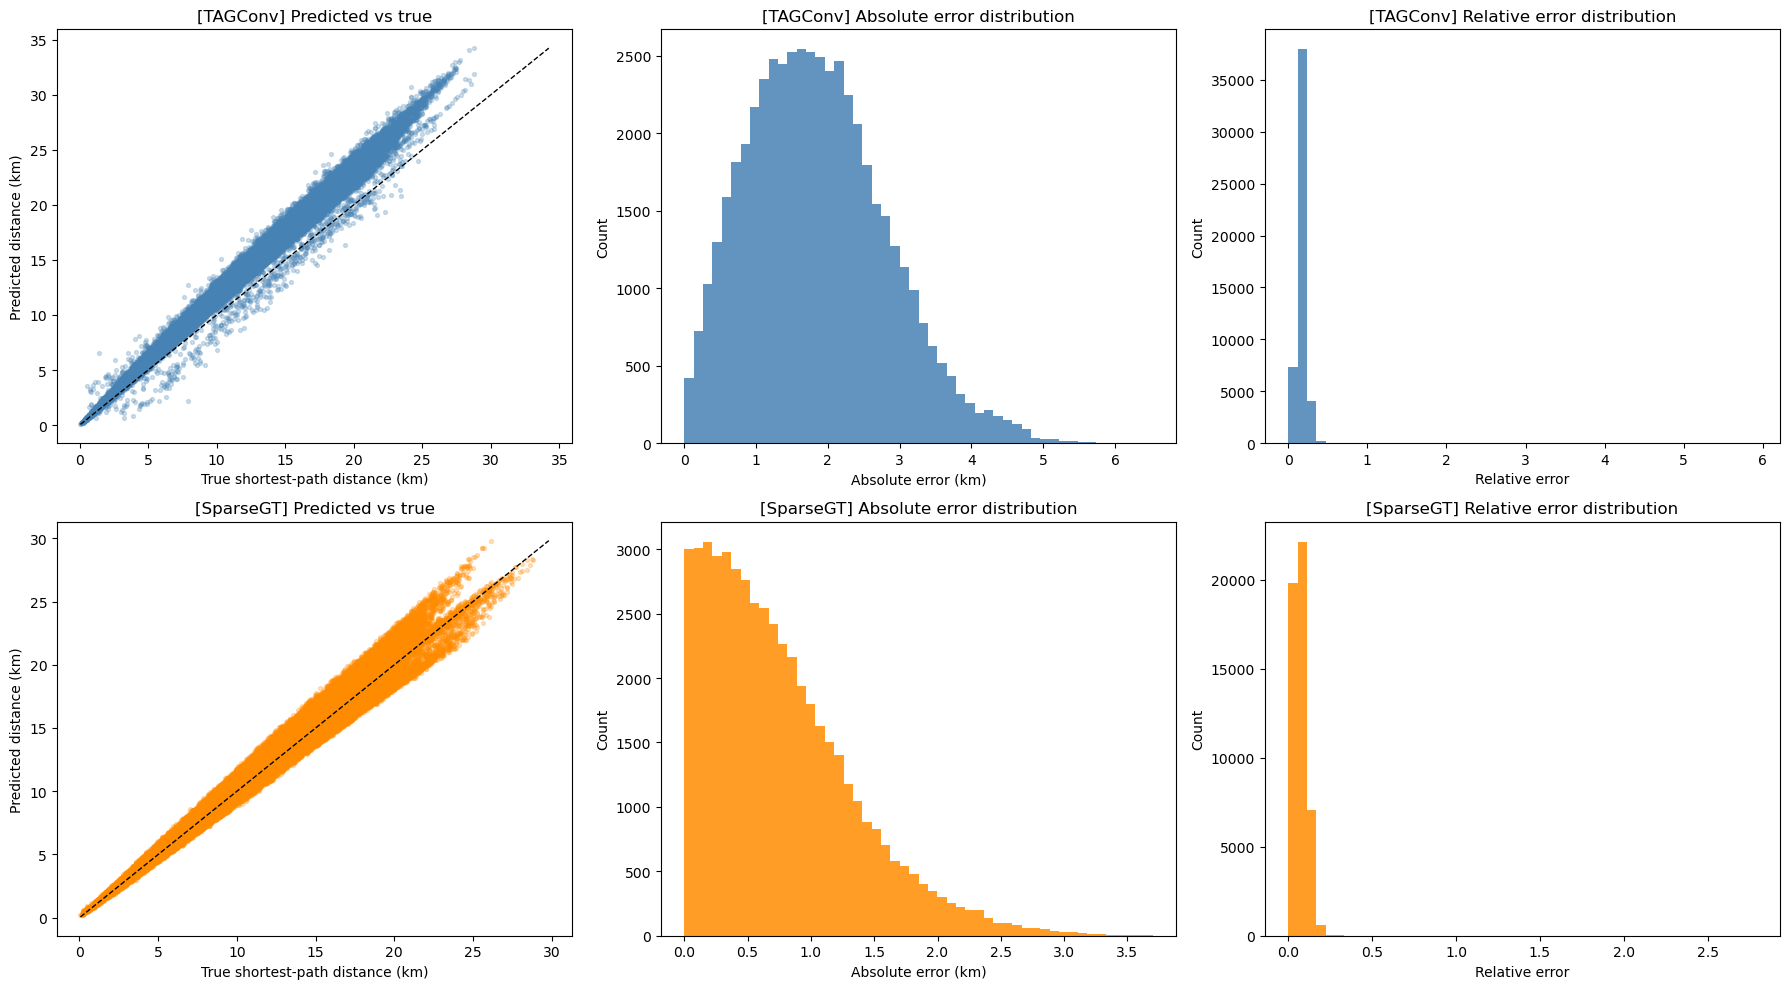

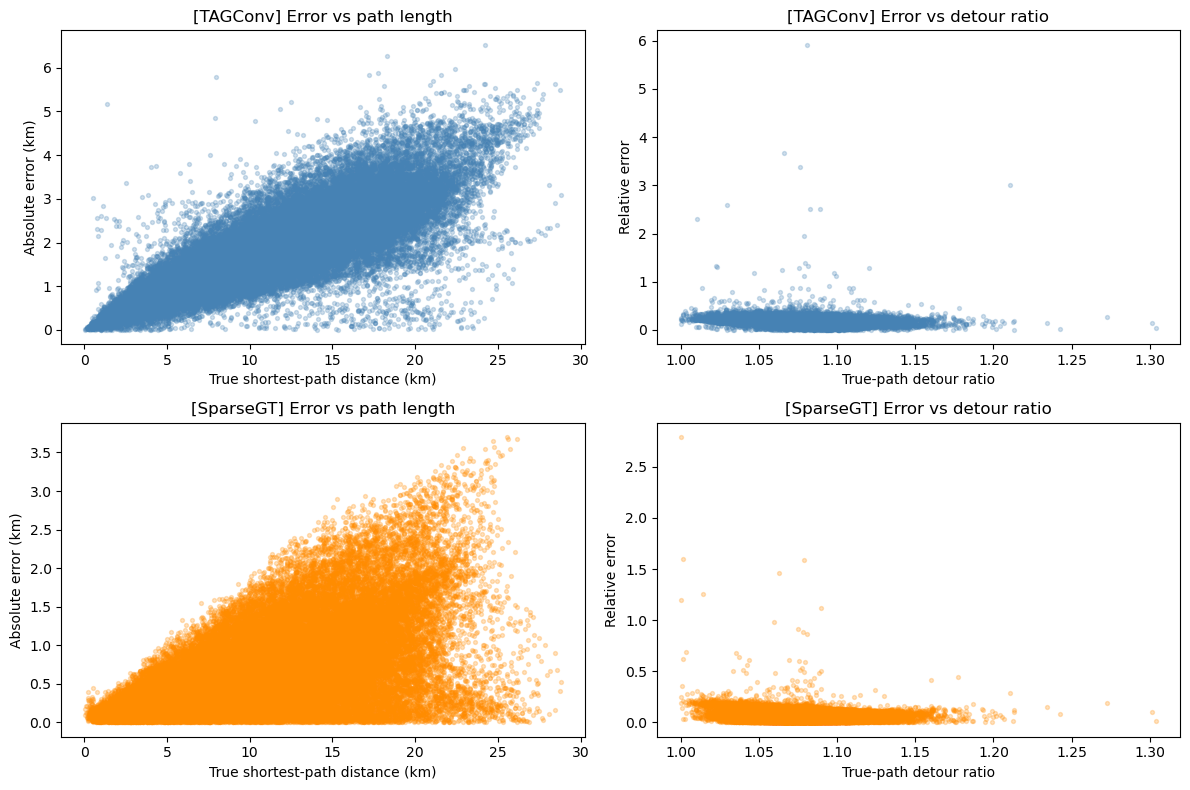

In [22]:
model_colors = {"TAGConv": "steelblue", "SparseGT": "darkorange"}
n_models = len(all_results)

fig, axes = plt.subplots(n_models, 3, figsize=(18, 5 * n_models), squeeze=False)

for row_idx, (name, res) in enumerate(all_results.items()):
    color = model_colors.get(name, "gray")
    ax_row = axes[row_idx]

    ax_row[0].scatter(res["lengths"], res["preds"], s=8, alpha=0.25, color=color)
    lims = [
        min(res["lengths"].min(), res["preds"].min()),
        max(res["lengths"].max(), res["preds"].max()),
    ]
    ax_row[0].plot(lims, lims, linestyle="--", color="black", linewidth=1)
    ax_row[0].set_xlabel("True shortest-path distance (km)")
    ax_row[0].set_ylabel("Predicted distance (km)")
    ax_row[0].set_title(f"[{name}] Predicted vs true")

    ax_row[1].hist(res["abs_err"], bins=50, color=color, alpha=0.85)
    ax_row[1].set_xlabel("Absolute error (km)")
    ax_row[1].set_ylabel("Count")
    ax_row[1].set_title(f"[{name}] Absolute error distribution")

    ax_row[2].hist(res["rel_err"], bins=50, color=color, alpha=0.85)
    ax_row[2].set_xlabel("Relative error")
    ax_row[2].set_ylabel("Count")
    ax_row[2].set_title(f"[{name}] Relative error distribution")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(n_models, 2, figsize=(12, 4 * n_models), squeeze=False)
for row_idx, (name, res) in enumerate(all_results.items()):
    color = model_colors.get(name, "gray")
    ax_row = axes[row_idx]

    ax_row[0].scatter(res["lengths"], res["abs_err"], s=8, alpha=0.25, color=color)
    ax_row[0].set_xlabel("True shortest-path distance (km)")
    ax_row[0].set_ylabel("Absolute error (km)")
    ax_row[0].set_title(f"[{name}] Error vs path length")

    ax_row[1].scatter(res["detour_ratio"], res["rel_err"], s=8, alpha=0.25, color=color)
    ax_row[1].set_xlabel("True-path detour ratio")
    ax_row[1].set_ylabel("Relative error")
    ax_row[1].set_title(f"[{name}] Error vs detour ratio")

plt.tight_layout()
plt.show()

In [23]:
def plot_prediction_pair(pair_idx: int, *, zoom_margin: float = 0.2):
    row = pred_results.loc[pred_results["pair_idx"] == pair_idx].iloc[0]
    fig, path_nodes = plot_pair(pair_idx, zoom_margin=zoom_margin)

    fig.suptitle(
        f"Pair {pair_idx}: pred={row['preds']:.3f} km, true={row['lengths']:.3f} km, "
        f"abs_err={row['abs_err']:.3f} km, rel_err={row['rel_err']:.3%}",
        y=1.02,
    )
    plt.tight_layout()
    return fig, path_nodes


worst_pairs = pred_results.sort_values(["rel_err", "abs_err"], ascending=False).head(10)
worst_pairs[
    [
        "pair_idx",
        "src",
        "tar",
        "preds",
        "lengths",
        "abs_err",
        "rel_err",
        "detour_ratio",
    ]
]

,pair_idx,src,tar,preds,lengths,abs_err,rel_err,detour_ratio
7704,35727,56499,58488,3.533449,0.510586,3.022863,5.920382,1.080707
38989,43229,472,7998,6.586124,1.411655,5.174470,3.665534,1.066379
12079,6267,241229,249733,3.313112,0.754948,2.558163,3.388528,1.076401
48345,43390,472,4959,3.090004,0.772341,2.317664,3.000830,1.210275
46417,43339,472,11971,3.622852,1.010929,2.611923,2.583685,1.029828
13105,35988,56499,68489,3.957066,1.126641,2.830425,2.512268,1.082708
11606,45454,9892,397,3.008568,0.859422,2.149147,2.500690,1.088973
14178,35845,56499,47982,3.289099,0.994490,2.294608,2.307321,1.010235
40000,35688,56499,69985,3.877705,1.312964,2.564742,1.953399,1.078638
35515,35701,56499,76486,4.352354,1.819355,2.532999,1.392251,1.079791


## Compare path categories

This section groups test pairs into three useful buckets:

- lowest-error paths
- highest-detour paths
- highest-error paths

That makes it easier to compare whether the model does best on simple routes and struggles more on paths that bend around terrain.

In [24]:
lowest_error_pairs = pred_results.sort_values(
    ["abs_err", "rel_err"], ascending=[True, True]
).head(10)

highest_detour_pairs = pred_results.sort_values(
    ["detour_ratio", "abs_err"], ascending=[False, False]
).head(10)

highest_error_pairs = pred_results.sort_values(
    ["rel_err", "abs_err"], ascending=[False, False]
).head(10)

comparison_columns = [
    "pair_idx",
    "src",
    "tar",
    "preds",
    "lengths",
    "abs_err",
    "rel_err",
    "detour_ratio",
]

print("Lowest-error paths")
display(lowest_error_pairs[comparison_columns])

print("Highest-detour paths")
display(highest_detour_pairs[comparison_columns])

print("Highest-error paths")
display(highest_error_pairs[comparison_columns])

Lowest-error paths


,pair_idx,src,tar,preds,lengths,abs_err,rel_err,detour_ratio
32071,45134,9892,18414,1.266262,1.266900,0.000638,0.000504,1.071906
46647,43163,472,85700,14.085314,14.084381,0.000933,0.000066,1.094736
44491,16821,112189,106640,2.288692,2.287698,0.000994,0.000434,1.138040
18759,42961,127118,134669,2.400686,2.404288,0.003603,0.001498,1.092927
49464,14090,19716,9687,1.667371,1.671008,0.003637,0.002177,1.059745
47138,23031,29718,1637,4.441816,4.446165,0.004350,0.000978,1.096353
3527,49873,187811,189319,0.385977,0.381276,0.004701,0.012329,1.083237
35177,11292,210834,205382,2.190393,2.195713,0.005320,0.002423,1.110150
20262,3207,82190,100122,3.404862,3.399401,0.005461,0.001606,1.092242
36394,13152,40080,43066,0.657916,0.663592,0.005675,0.008553,1.082566


Highest-detour paths


,pair_idx,src,tar,preds,lengths,abs_err,rel_err,detour_ratio
10724,8596,51807,48299,0.534318,0.554767,0.020449,0.036860,1.304048
29755,44742,69898,60908,1.235462,1.082460,0.153003,0.141347,1.301259
36840,10563,4960,2472,0.852162,0.669380,0.182782,0.273062,1.272620
32432,46984,106344,111854,0.736549,0.748139,0.011591,0.015493,1.242701
423,14517,230647,239140,1.052570,0.912985,0.139585,0.152888,1.234444
48038,39777,131401,121404,1.022242,1.013403,0.008840,0.008723,1.212885
27854,30404,12834,29314,2.239566,1.873070,0.366496,0.195666,1.212881
35450,30133,12834,17812,1.361263,1.174256,0.187007,0.159256,1.212608
48345,43390,472,4959,3.090004,0.772341,2.317664,3.000830,1.210275
9011,28015,11938,35961,2.954663,2.585456,0.369208,0.142802,1.206990


Highest-error paths


,pair_idx,src,tar,preds,lengths,abs_err,rel_err,detour_ratio
7704,35727,56499,58488,3.533449,0.510586,3.022863,5.920382,1.080707
38989,43229,472,7998,6.586124,1.411655,5.174470,3.665534,1.066379
12079,6267,241229,249733,3.313112,0.754948,2.558163,3.388528,1.076401
48345,43390,472,4959,3.090004,0.772341,2.317664,3.000830,1.210275
46417,43339,472,11971,3.622852,1.010929,2.611923,2.583685,1.029828
13105,35988,56499,68489,3.957066,1.126641,2.830425,2.512268,1.082708
11606,45454,9892,397,3.008568,0.859422,2.149147,2.500690,1.088973
14178,35845,56499,47982,3.289099,0.994490,2.294608,2.307321,1.010235
40000,35688,56499,69985,3.877705,1.312964,2.564742,1.953399,1.078638
35515,35701,56499,76486,4.352354,1.819355,2.532999,1.392251,1.079791


Lowest-error paths


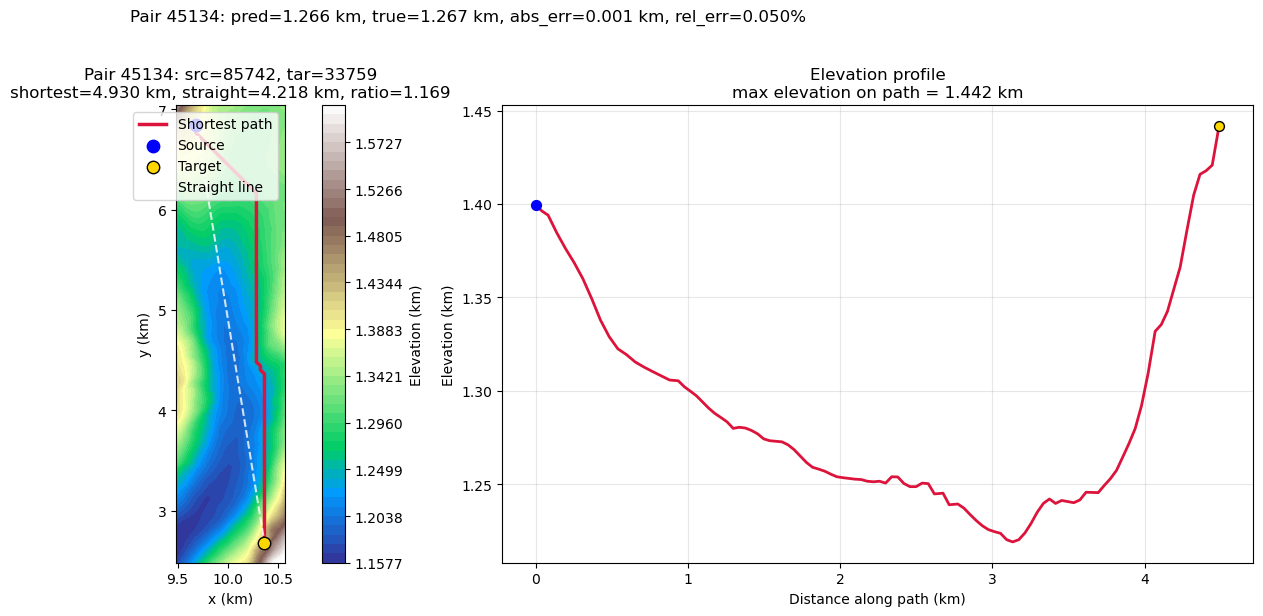

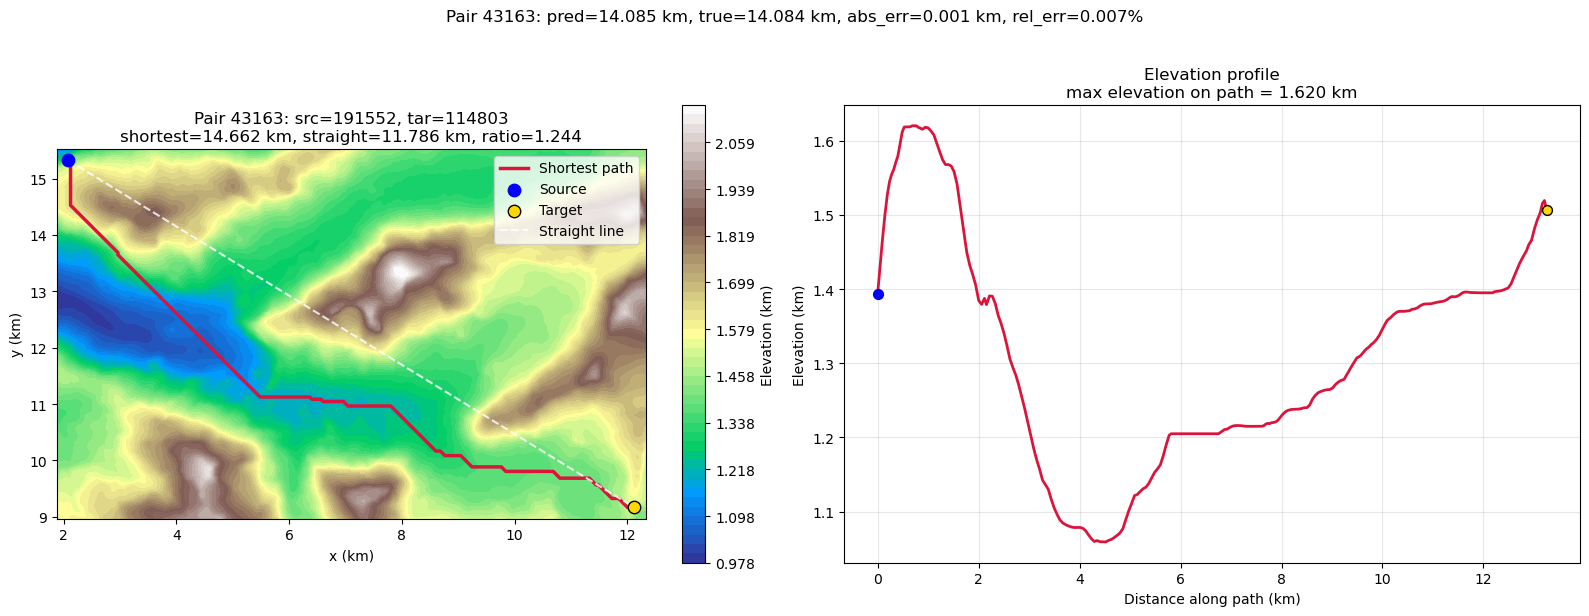

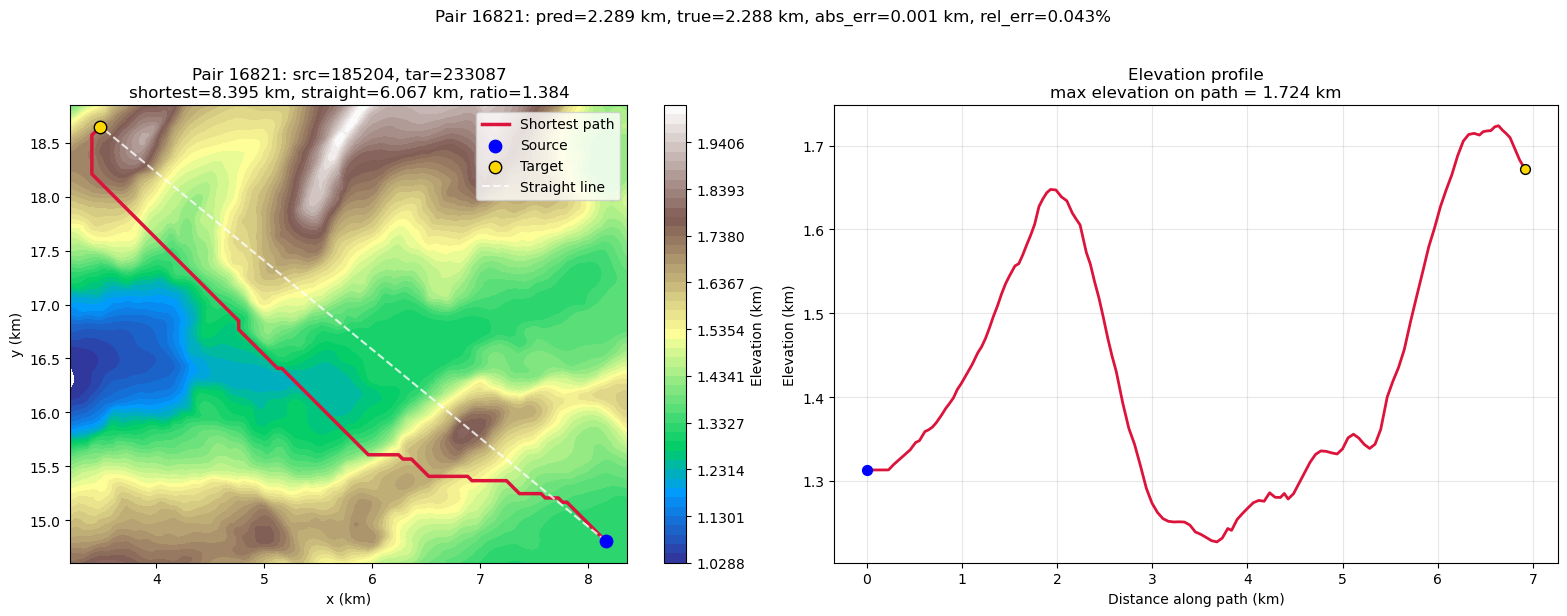

Highest-detour paths


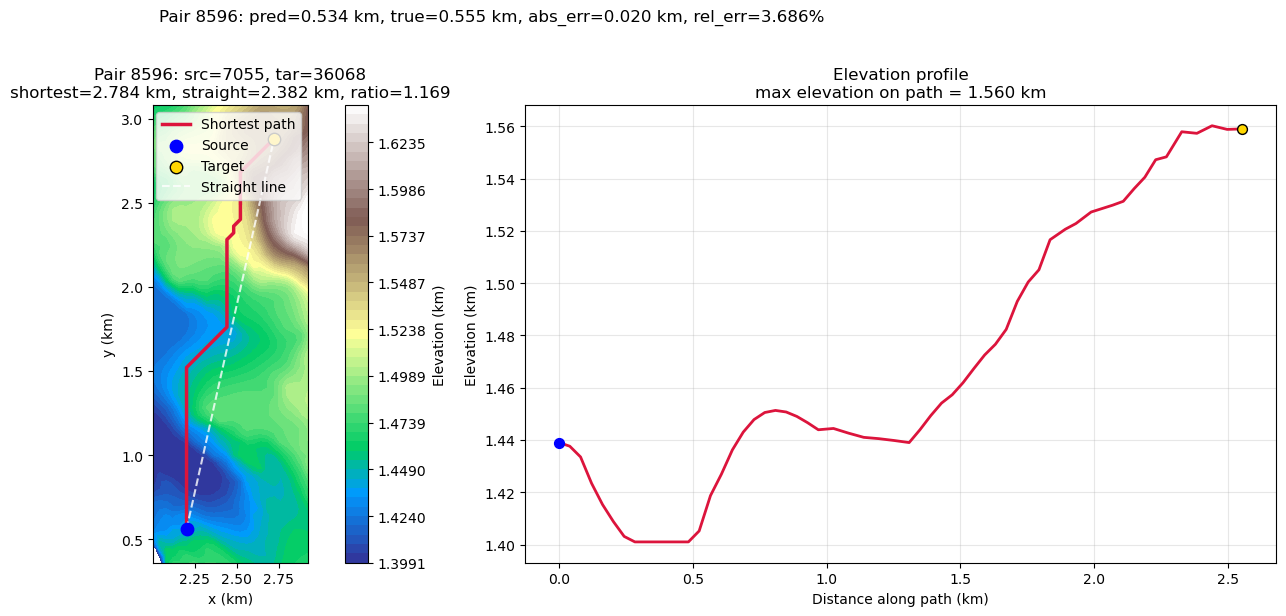

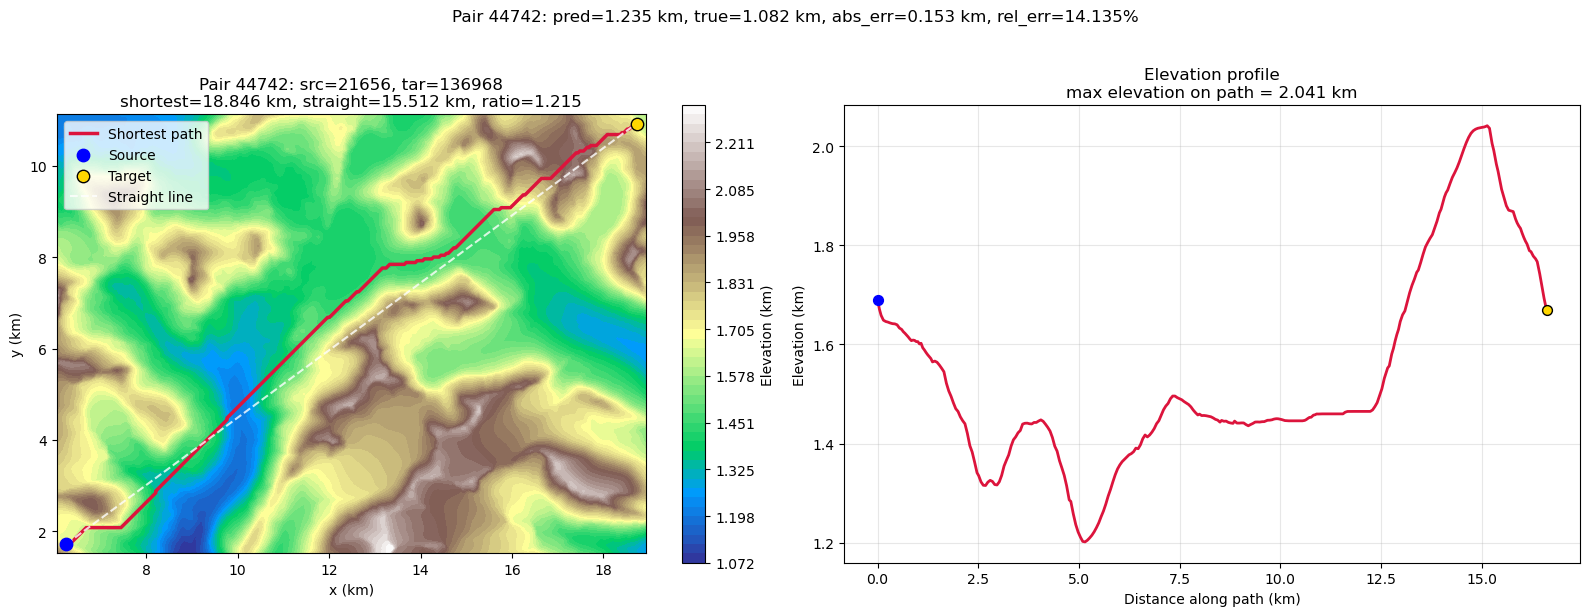

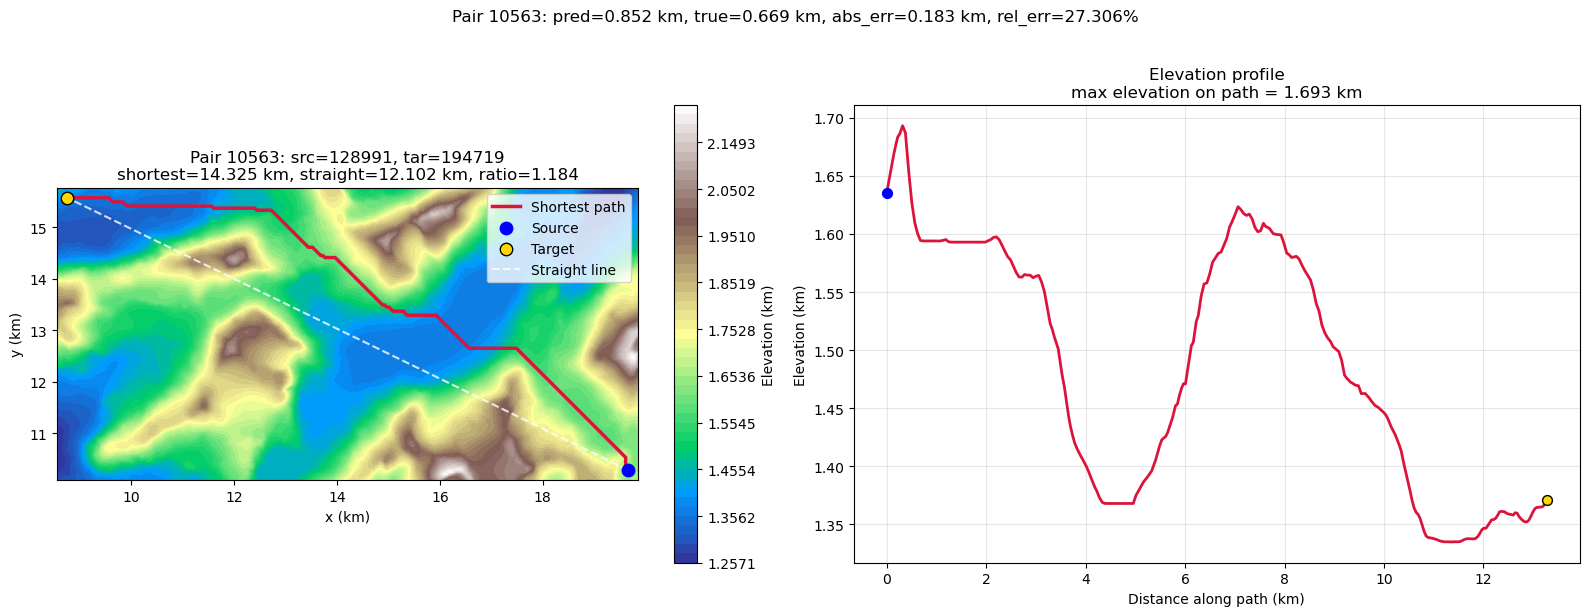

Highest-error paths


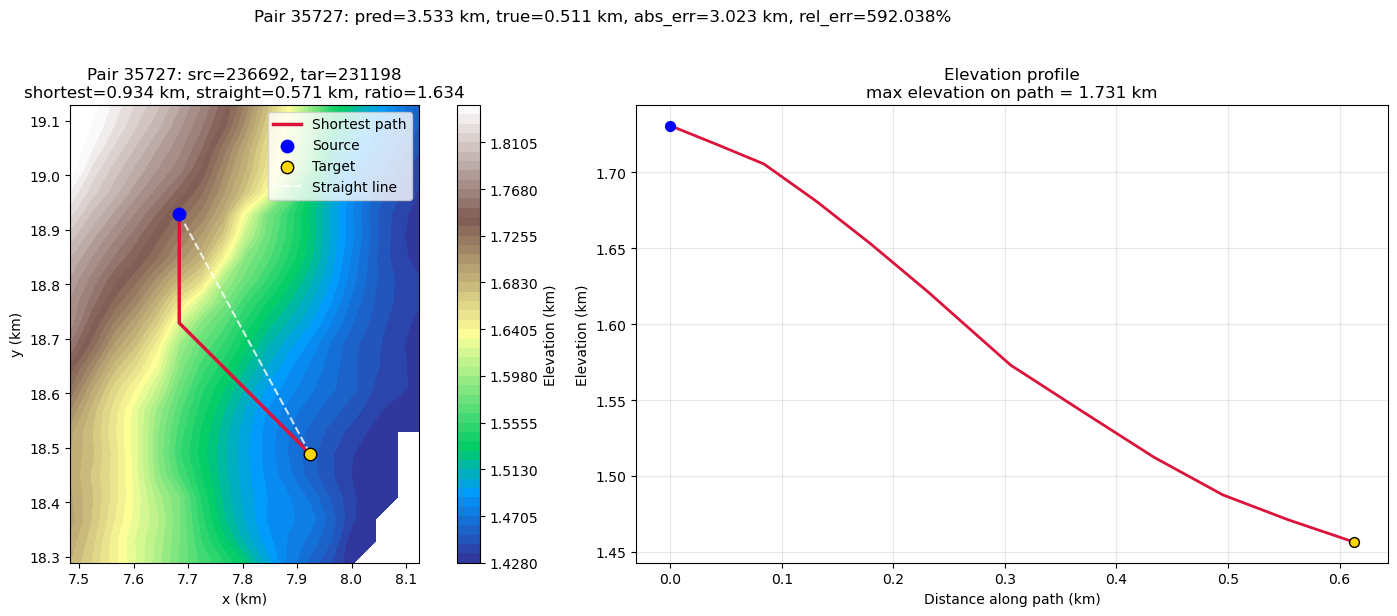

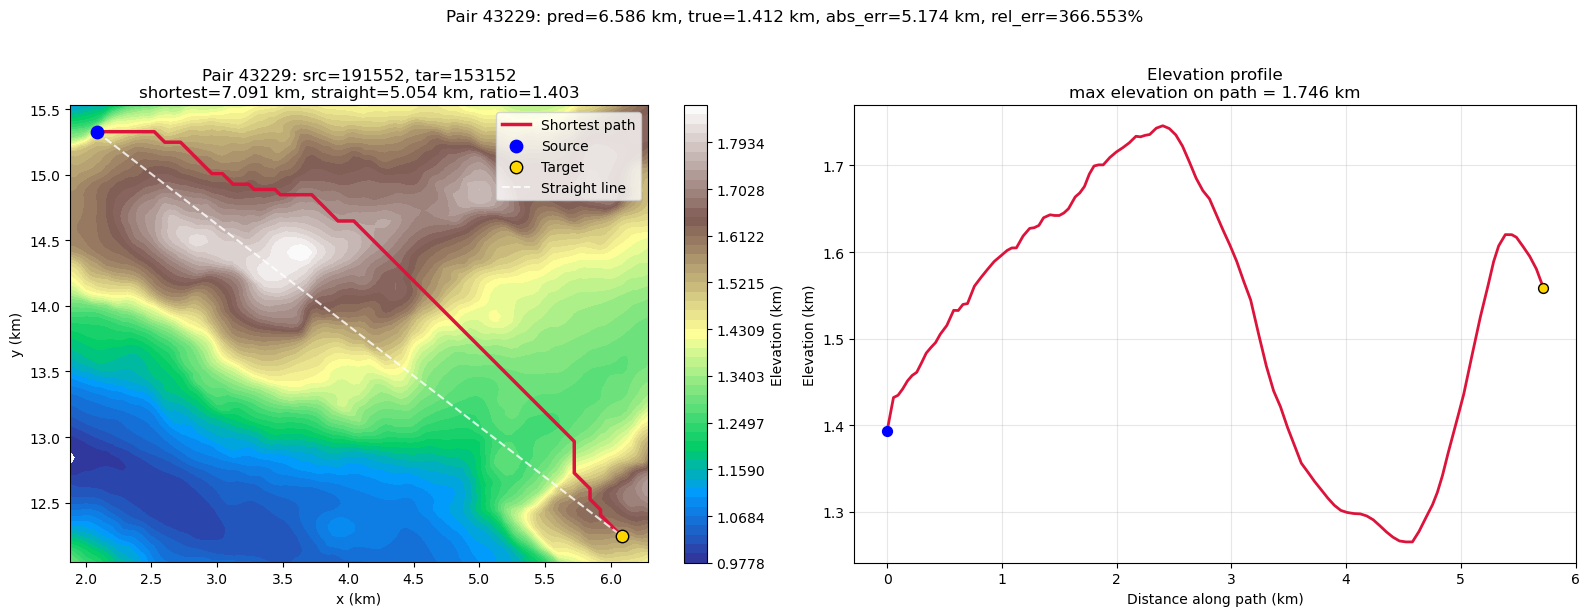

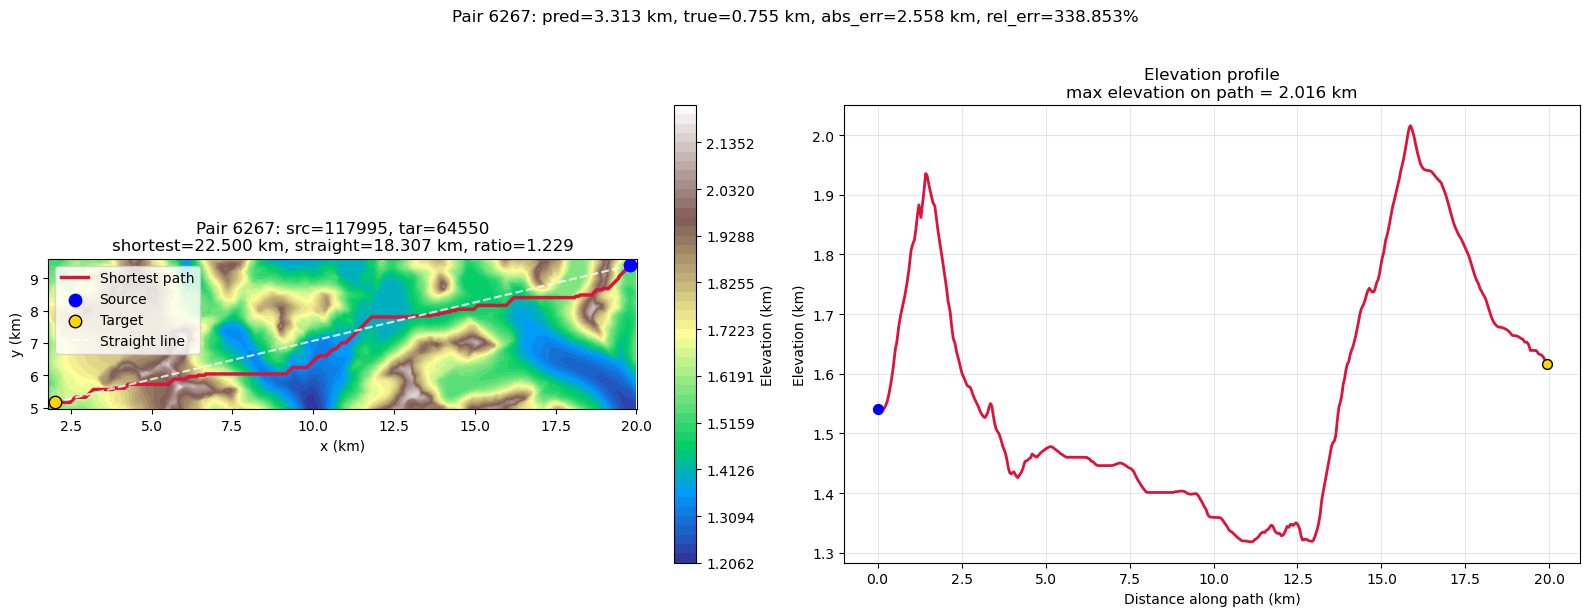

In [25]:
def plot_pair_group(group_name: str, group_df: pd.DataFrame, n_examples: int = 3):
    print(group_name)
    for pair_idx in group_df["pair_idx"].head(n_examples):
        fig, path_nodes = plot_prediction_pair(int(pair_idx))
        plt.show()


plot_pair_group("Lowest-error paths", lowest_error_pairs)
plot_pair_group("Highest-detour paths", highest_detour_pairs)
plot_pair_group("Highest-error paths", highest_error_pairs)

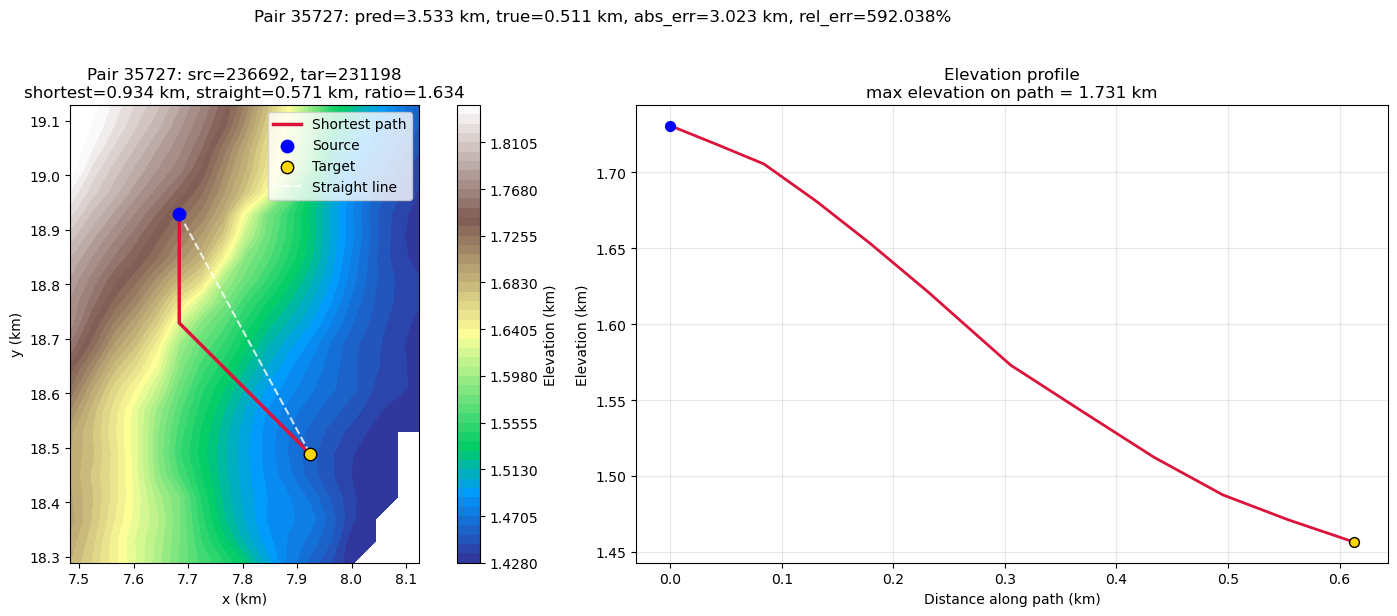

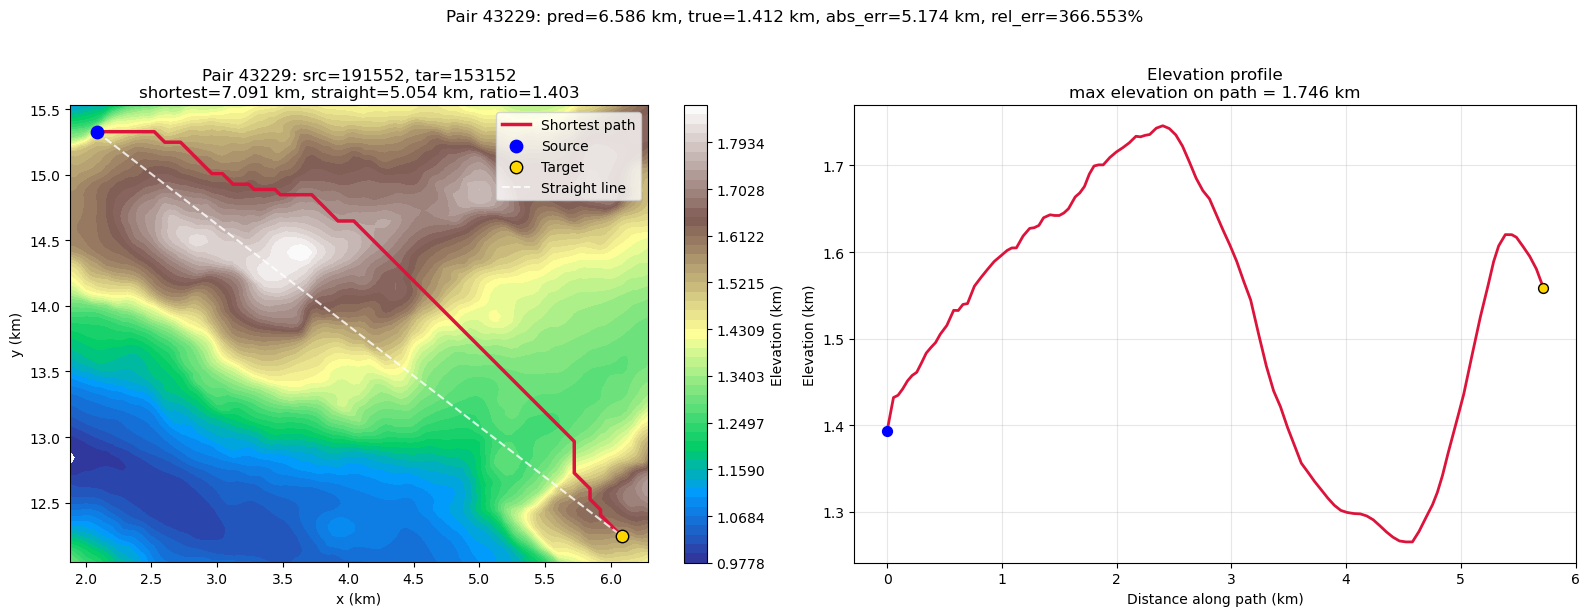

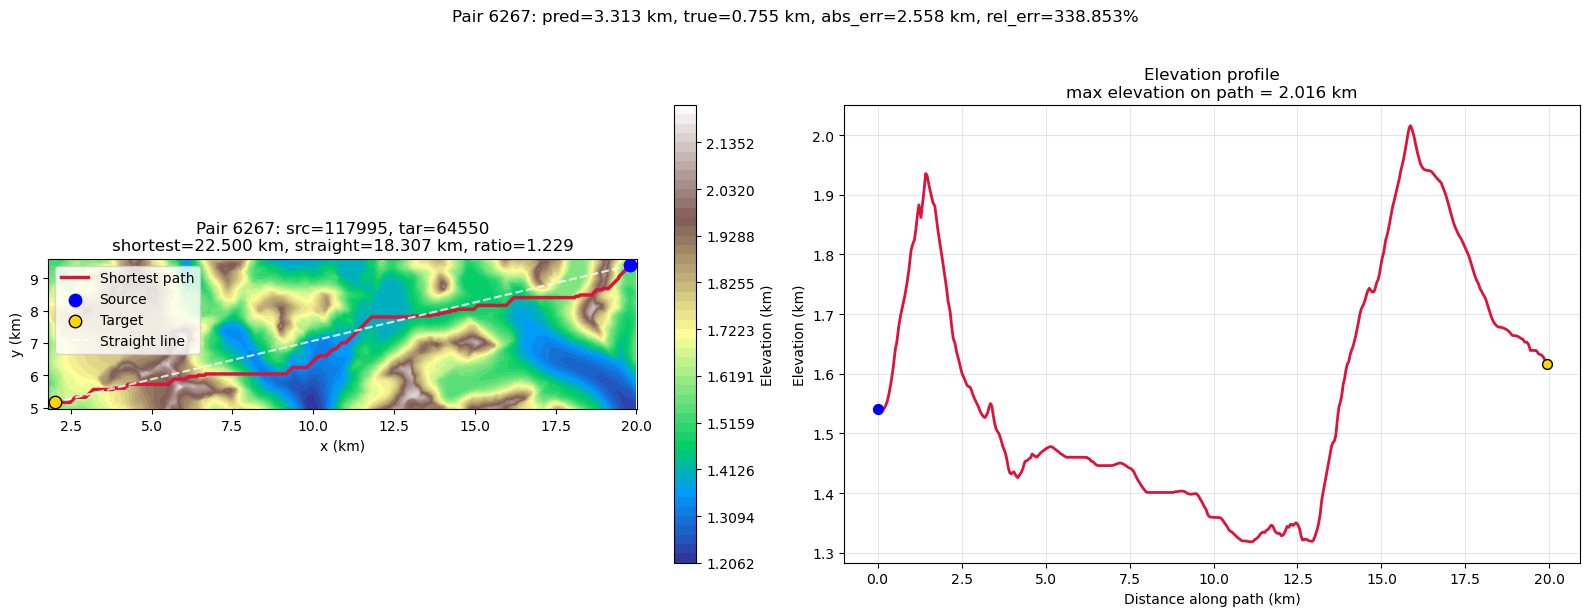

Path has 12 nodes


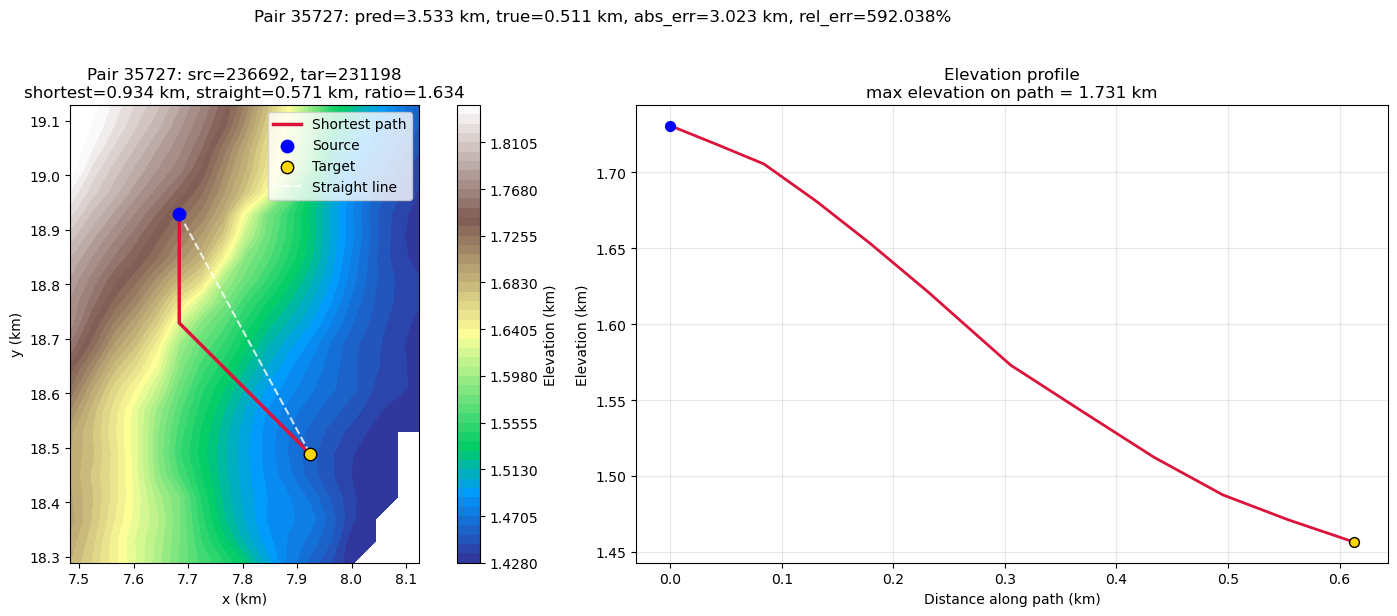

In [26]:
for pair_idx in worst_pairs["pair_idx"].head(3):
    fig, path_nodes = plot_prediction_pair(int(pair_idx))
    plt.show()

PAIR_IDX = int(worst_pairs.iloc[0]["pair_idx"])
fig, path_nodes = plot_prediction_pair(PAIR_IDX)
print(f"Path has {len(path_nodes)} nodes")
plt.show()

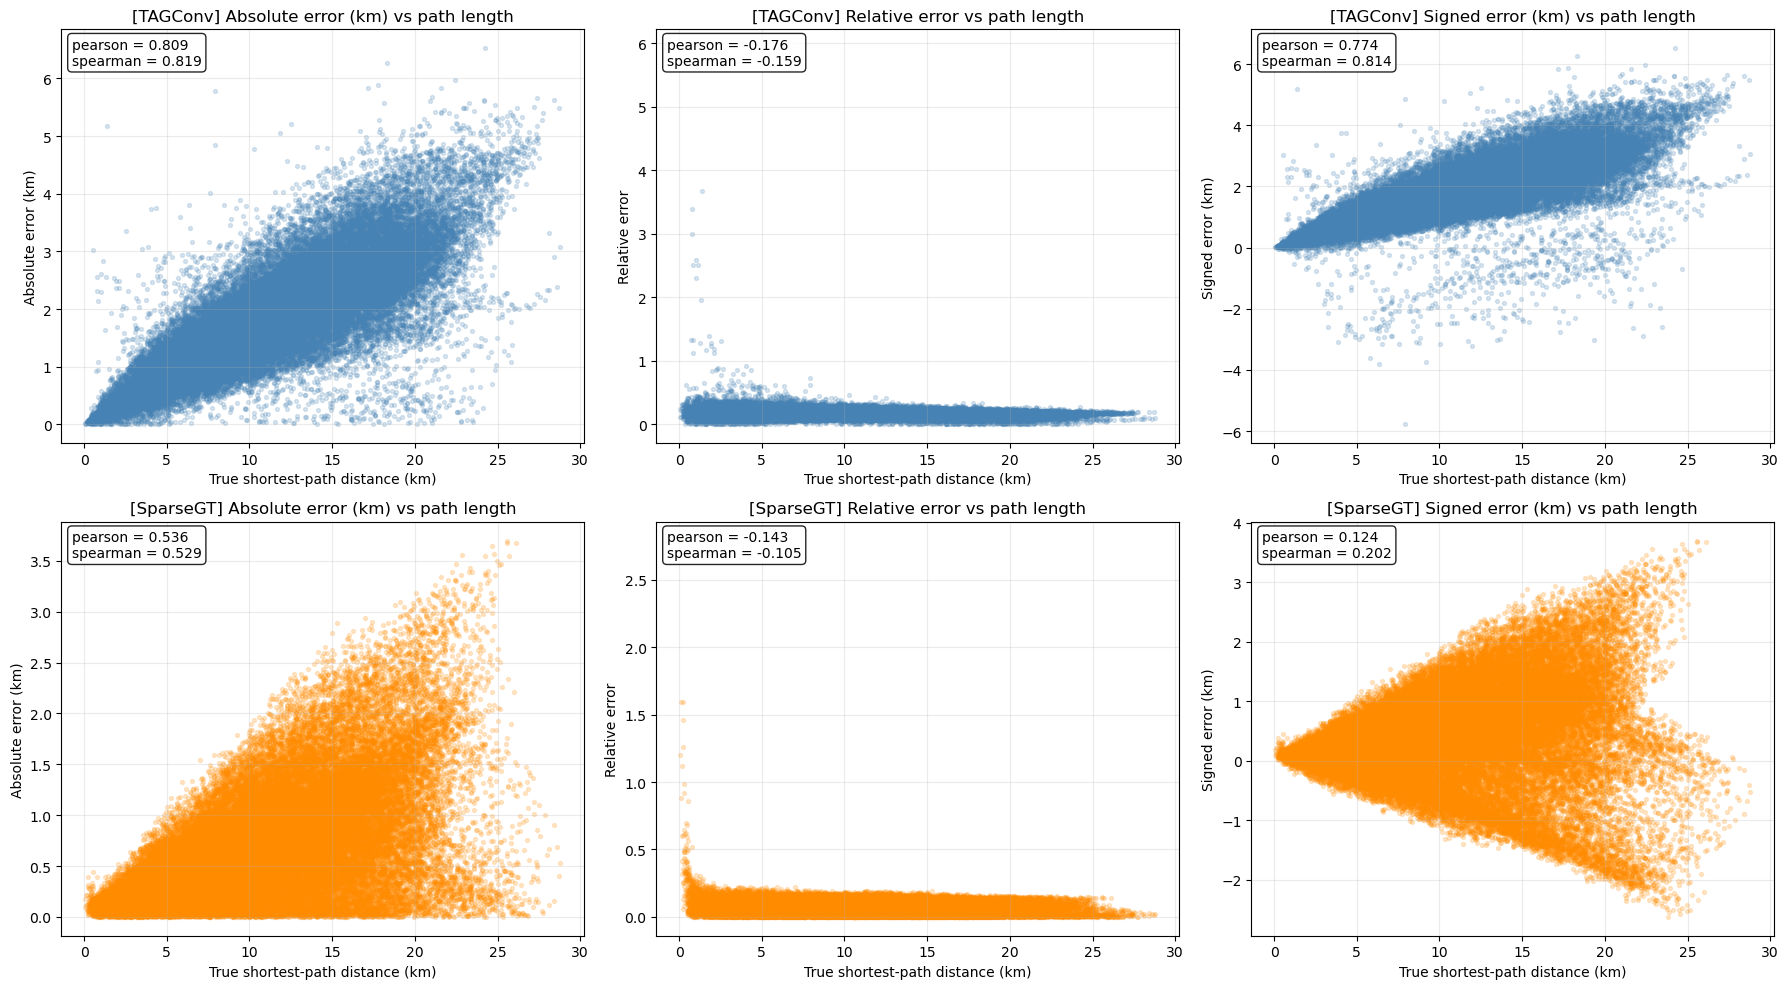

In [27]:
metrics = [
    ("abs_err", "Absolute error (km)"),
    ("rel_err", "Relative error"),
    ("signed_err", "Signed error (km)"),
]

fig, axes = plt.subplots(n_models, 3, figsize=(18, 5 * n_models), squeeze=False)

for row_idx, (name, res) in enumerate(all_results.items()):
    color = model_colors.get(name, "gray")
    for col_idx, (col, ylabel) in enumerate(metrics):
        ax = axes[row_idx, col_idx]
        x = res["lengths"]
        y = res[col]

        ax.scatter(x, y, s=8, alpha=0.2, color=color)
        ax.set_xlabel("True shortest-path distance (km)")
        ax.set_ylabel(ylabel)
        ax.set_title(f"[{name}] {ylabel} vs path length")
        ax.grid(alpha=0.25)

        pearson = x.corr(y, method="pearson")
        spearman = x.corr(y, method="spearman")
        ax.text(
            0.02, 0.98,
            f"pearson = {pearson:.3f}\nspearman = {spearman:.3f}",
            transform=ax.transAxes, va="top", ha="left",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.85),
        )

plt.tight_layout()

## Targeted analysis: close-point and high-elevation performance

The key question: does **proximity-variance sampling** improve prediction for

1. **Close-together pairs** (short straight-line distance)?
2. **High-elevation / steep-terrain pairs** (high altitude variance at source/target)?

The plots below break down error by straight-line distance and by elevation gradient
so you can compare against the uniform-sampling baseline in `plot_shortest_path.ipynb`.

In [28]:
test_data = np.load(TEST_DATA_PATH)
test_nf = test_data["node_features"]
test_alt_var = compute_altitude_variance(test_nf, *infer_grid(test_nf)[2].shape)

for name, res in all_results.items():
    res["src_elevation"] = test_nf[res["src"].to_numpy(), 2]
    res["tar_elevation"] = test_nf[res["tar"].to_numpy(), 2]
    res["max_elevation"] = np.maximum(res["src_elevation"], res["tar_elevation"])
    res["mean_elevation"] = (res["src_elevation"] + res["tar_elevation"]) / 2
    res["src_alt_var"] = test_alt_var[res["src"].to_numpy()]
    res["tar_alt_var"] = test_alt_var[res["tar"].to_numpy()]
    res["max_alt_var"] = np.maximum(res["src_alt_var"], res["tar_alt_var"])
    res["mean_alt_var"] = (res["src_alt_var"] + res["tar_alt_var"]) / 2

# Keep pred_results up to date
pred_results = all_results["TAGConv"] if "TAGConv" in all_results else list(all_results.values())[0]
print("Feature columns added for all models.")

Feature columns added for all models.


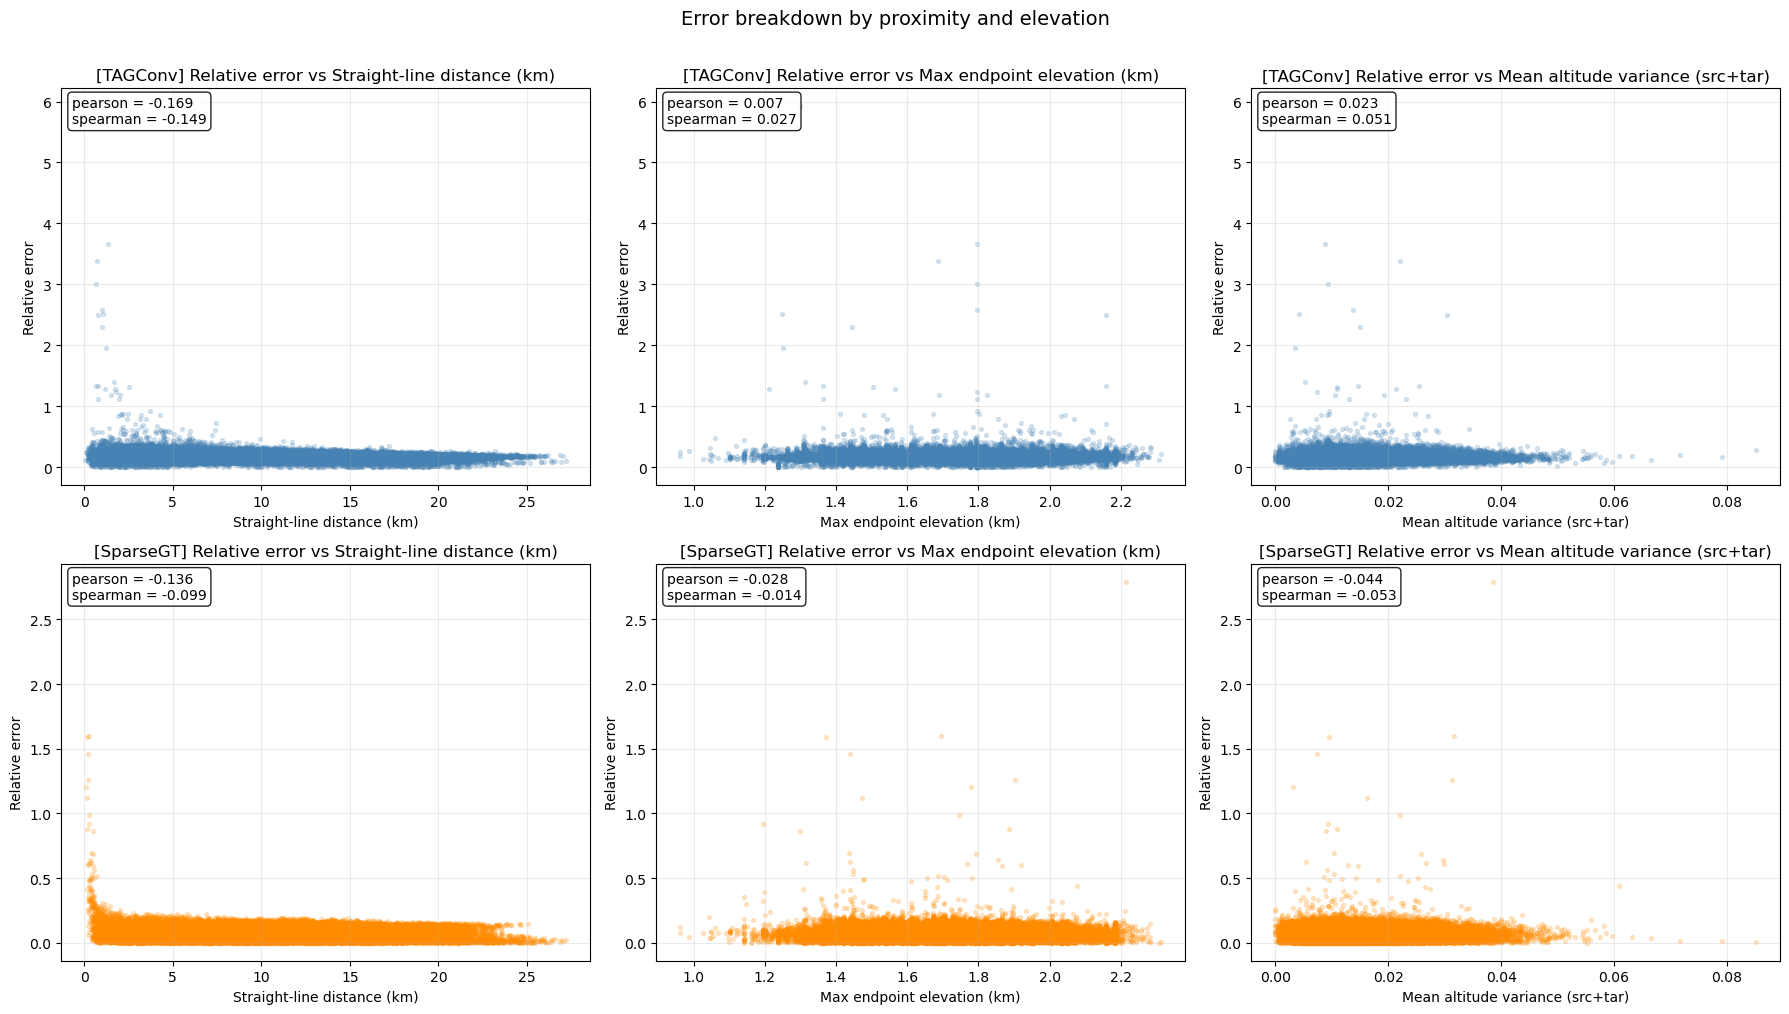

In [29]:
scatter_specs = [
    ("straight_line", "rel_err", "Straight-line distance (km)", "Relative error"),
    ("max_elevation", "rel_err", "Max endpoint elevation (km)", "Relative error"),
    ("mean_alt_var", "rel_err", "Mean altitude variance (src+tar)", "Relative error"),
]

fig, axes = plt.subplots(n_models, len(scatter_specs),
                         figsize=(6 * len(scatter_specs), 5 * n_models), squeeze=False)

for row_idx, (name, res) in enumerate(all_results.items()):
    color = model_colors.get(name, "gray")
    for col_idx, (xcol, ycol, xlabel, ylabel) in enumerate(scatter_specs):
        ax = axes[row_idx, col_idx]
        x = res[xcol]
        y = res[ycol]
        ax.scatter(x, y, s=8, alpha=0.2, color=color)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.set_title(f"[{name}] {ylabel} vs {xlabel}")
        ax.grid(alpha=0.25)

        pearson = x.corr(y, method="pearson")
        spearman = x.corr(y, method="spearman")
        ax.text(
            0.02, 0.98,
            f"pearson = {pearson:.3f}\nspearman = {spearman:.3f}",
            transform=ax.transAxes, va="top", ha="left",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.85),
        )

plt.suptitle("Error breakdown by proximity and elevation", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

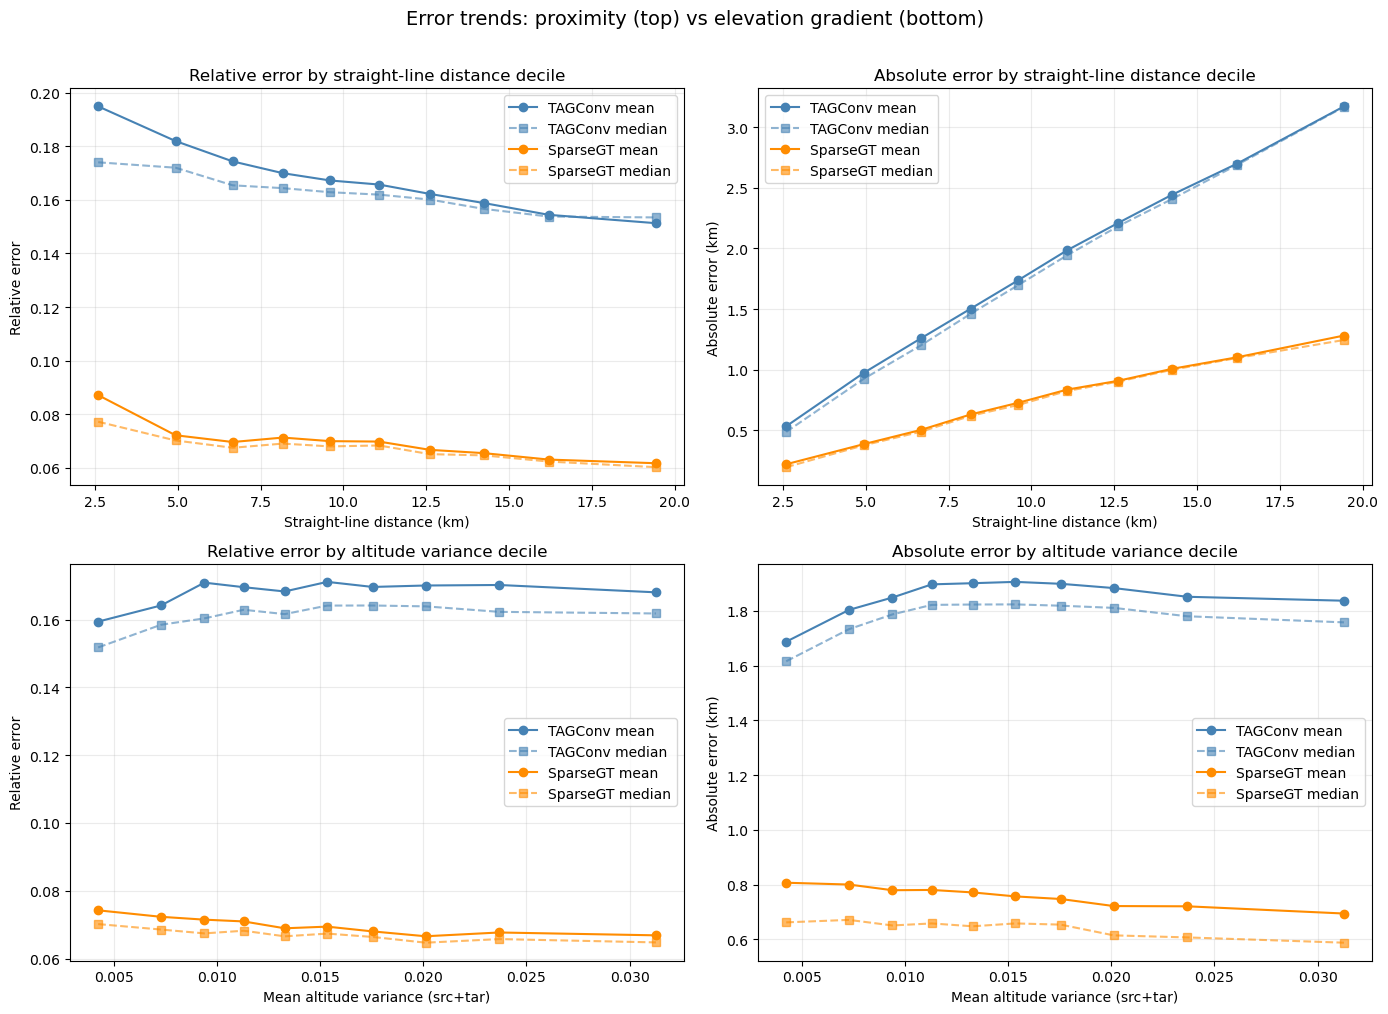

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# --- Row 1: relative error by straight-line distance decile (overlaid) ---
for name, res in all_results.items():
    color = model_colors.get(name, "gray")
    binned = res.copy()
    binned["dist_bin"] = pd.qcut(binned["straight_line"], q=10, duplicates="drop")
    trend = (
        binned.groupby("dist_bin", observed=False)
        .agg(mean_dist=("straight_line", "mean"),
             mean_rel_err=("rel_err", "mean"),
             median_rel_err=("rel_err", "median"))
        .reset_index(drop=True)
    )
    axes[0, 0].plot(trend["mean_dist"], trend["mean_rel_err"], marker="o", label=f"{name} mean", color=color)
    axes[0, 0].plot(trend["mean_dist"], trend["median_rel_err"], marker="s", linestyle="--",
                    label=f"{name} median", color=color, alpha=0.6)

axes[0, 0].set_xlabel("Straight-line distance (km)")
axes[0, 0].set_ylabel("Relative error")
axes[0, 0].set_title("Relative error by straight-line distance decile")
axes[0, 0].grid(alpha=0.25)
axes[0, 0].legend()

# --- Row 1, col 2: absolute error by distance decile ---
for name, res in all_results.items():
    color = model_colors.get(name, "gray")
    binned = res.copy()
    binned["dist_bin"] = pd.qcut(binned["straight_line"], q=10, duplicates="drop")
    trend = (
        binned.groupby("dist_bin", observed=False)
        .agg(mean_dist=("straight_line", "mean"),
             mean_abs_err=("abs_err", "mean"),
             median_abs_err=("abs_err", "median"))
        .reset_index(drop=True)
    )
    axes[0, 1].plot(trend["mean_dist"], trend["mean_abs_err"], marker="o", label=f"{name} mean", color=color)
    axes[0, 1].plot(trend["mean_dist"], trend["median_abs_err"], marker="s", linestyle="--",
                    label=f"{name} median", color=color, alpha=0.6)

axes[0, 1].set_xlabel("Straight-line distance (km)")
axes[0, 1].set_ylabel("Absolute error (km)")
axes[0, 1].set_title("Absolute error by straight-line distance decile")
axes[0, 1].grid(alpha=0.25)
axes[0, 1].legend()

# --- Row 2: relative error by altitude variance decile ---
for name, res in all_results.items():
    color = model_colors.get(name, "gray")
    binned = res.copy()
    binned["alt_var_bin"] = pd.qcut(binned["mean_alt_var"], q=10, duplicates="drop")
    trend = (
        binned.groupby("alt_var_bin", observed=False)
        .agg(mean_alt_var=("mean_alt_var", "mean"),
             mean_rel_err=("rel_err", "mean"),
             median_rel_err=("rel_err", "median"))
        .reset_index(drop=True)
    )
    axes[1, 0].plot(trend["mean_alt_var"], trend["mean_rel_err"], marker="o", label=f"{name} mean", color=color)
    axes[1, 0].plot(trend["mean_alt_var"], trend["median_rel_err"], marker="s", linestyle="--",
                    label=f"{name} median", color=color, alpha=0.6)

axes[1, 0].set_xlabel("Mean altitude variance (src+tar)")
axes[1, 0].set_ylabel("Relative error")
axes[1, 0].set_title("Relative error by altitude variance decile")
axes[1, 0].grid(alpha=0.25)
axes[1, 0].legend()

# --- Row 2, col 2: absolute error by altitude variance decile ---
for name, res in all_results.items():
    color = model_colors.get(name, "gray")
    binned = res.copy()
    binned["alt_var_bin"] = pd.qcut(binned["mean_alt_var"], q=10, duplicates="drop")
    trend = (
        binned.groupby("alt_var_bin", observed=False)
        .agg(mean_alt_var=("mean_alt_var", "mean"),
             mean_abs_err=("abs_err", "mean"),
             median_abs_err=("abs_err", "median"))
        .reset_index(drop=True)
    )
    axes[1, 1].plot(trend["mean_alt_var"], trend["mean_abs_err"], marker="o", label=f"{name} mean", color=color)
    axes[1, 1].plot(trend["mean_alt_var"], trend["median_abs_err"], marker="s", linestyle="--",
                    label=f"{name} median", color=color, alpha=0.6)

axes[1, 1].set_xlabel("Mean altitude variance (src+tar)")
axes[1, 1].set_ylabel("Absolute error (km)")
axes[1, 1].set_title("Absolute error by altitude variance decile")
axes[1, 1].grid(alpha=0.25)
axes[1, 1].legend()

plt.suptitle("Error trends: proximity (top) vs elevation gradient (bottom)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

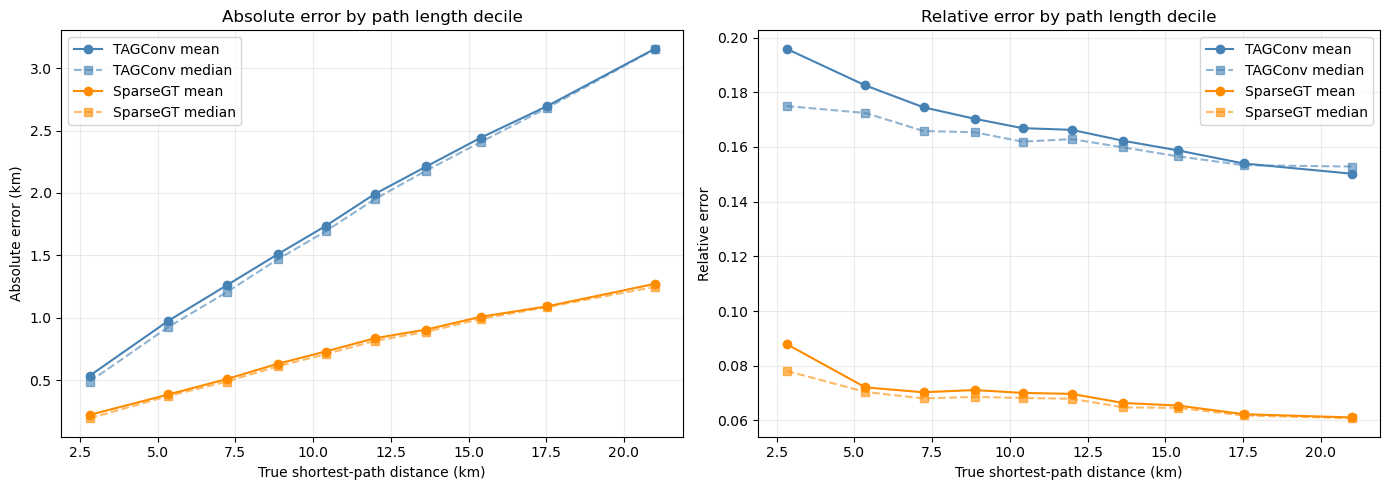

In [31]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for name, res in all_results.items():
    color = model_colors.get(name, "gray")
    binned = res.copy()
    binned["length_bin"] = pd.qcut(binned["lengths"], q=10, duplicates="drop")
    trend = (
        binned.groupby("length_bin", observed=False)
        .agg(mean_length=("lengths", "mean"),
             mean_abs_err=("abs_err", "mean"),
             median_abs_err=("abs_err", "median"),
             mean_rel_err=("rel_err", "mean"),
             median_rel_err=("rel_err", "median"))
        .reset_index(drop=True)
    )
    ax1.plot(trend["mean_length"], trend["mean_abs_err"], marker="o", label=f"{name} mean", color=color)
    ax1.plot(trend["mean_length"], trend["median_abs_err"], marker="s", linestyle="--",
             label=f"{name} median", color=color, alpha=0.6)
    ax2.plot(trend["mean_length"], trend["mean_rel_err"], marker="o", label=f"{name} mean", color=color)
    ax2.plot(trend["mean_length"], trend["median_rel_err"], marker="s", linestyle="--",
             label=f"{name} median", color=color, alpha=0.6)

ax1.set_xlabel("True shortest-path distance (km)")
ax1.set_ylabel("Absolute error (km)")
ax1.set_title("Absolute error by path length decile")
ax1.legend()
ax1.grid(alpha=0.25)

ax2.set_xlabel("True shortest-path distance (km)")
ax2.set_ylabel("Relative error")
ax2.set_title("Relative error by path length decile")
ax2.legend()
ax2.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## Dataset sampling distribution

Visualize where the proximity-variance sampler placed sources and targets on the terrain.
This confirms whether high-gradient regions and close pairs are indeed over-represented.

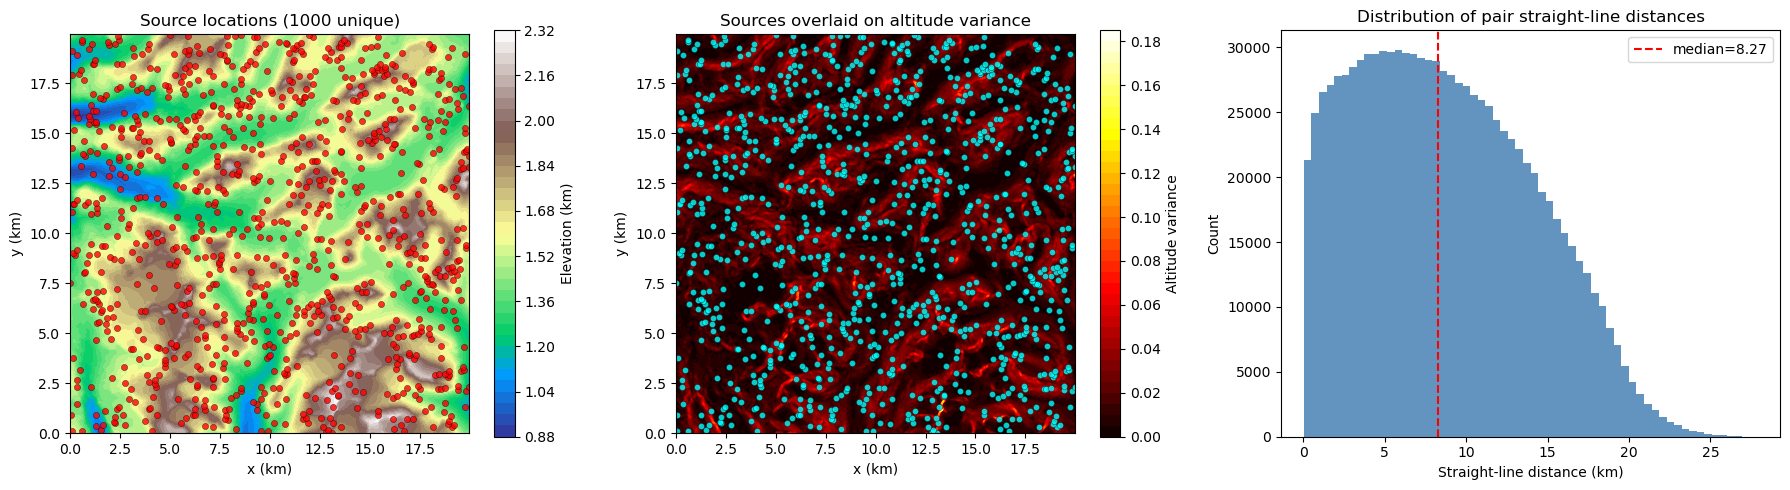

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Source locations on terrain
terrain = axes[0].contourf(x_grid, y_grid, z_grid, levels=40, cmap="terrain")
fig.colorbar(terrain, ax=axes[0], label="Elevation (km)")
unique_srcs = np.unique(srcs)
axes[0].scatter(
    node_features[unique_srcs, 0], node_features[unique_srcs, 1],
    color="red", s=20, alpha=0.8, edgecolor="black", linewidth=0.3,
)
axes[0].set_title(f"Source locations ({len(unique_srcs)} unique)")
axes[0].set_xlabel("x (km)")
axes[0].set_ylabel("y (km)")
axes[0].set_aspect("equal")

# Altitude variance heatmap
alt_var_grid = alt_var.reshape(rows, cols)
im = axes[1].contourf(x_grid, y_grid, alt_var_grid, levels=40, cmap="hot")
fig.colorbar(im, ax=axes[1], label="Altitude variance")
axes[1].scatter(
    node_features[unique_srcs, 0], node_features[unique_srcs, 1],
    color="cyan", s=20, alpha=0.8, edgecolor="black", linewidth=0.3,
)
axes[1].set_title("Sources overlaid on altitude variance")
axes[1].set_xlabel("x (km)")
axes[1].set_ylabel("y (km)")
axes[1].set_aspect("equal")

# Straight-line distance histogram
straight_line_dists = np.linalg.norm(node_features[tars] - node_features[srcs], axis=1)
axes[2].hist(straight_line_dists, bins=60, color="steelblue", alpha=0.85)
axes[2].set_xlabel("Straight-line distance (km)")
axes[2].set_ylabel("Count")
axes[2].set_title("Distribution of pair straight-line distances")
axes[2].axvline(np.median(straight_line_dists), color="red", linestyle="--", label=f"median={np.median(straight_line_dists):.2f}")
axes[2].legend()

plt.tight_layout()
plt.show()